In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "00_EDA_tong_hop_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 01:41:06 | INFO | Bắt đầu chạy 00_EDA_tong_hop_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0141_00_EDA_tong_hop_Han.log


# EDA tổng hợp E0.1 → E0.8 (Dự báo điện năng hộ gia đình)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 – sinh tự động bằng `notebooks/eda_notebooks/gop_eda.py` từ 8 notebook con |
| **Đọc vào** | `data/raw/individual+household+electric+power+consumption.zip`, `data/processed/hourly_clean.csv` |
| **Ghi ra** | Giống 8 notebook con, cộng thêm `data/eda_data/eda_00_kho_khan_xu_ly.csv`, `data/eda_data/eda_goi_y_nhan_xet.md`, `data/eda_data/eda_00_tom_tat.txt` |
| **Chạy sau** | `01_cleaning.ipynb` (cần `hourly_clean.csv` cho phần E0.4 → E0.8) |

Đây là **bản chính thức đọc từ trên xuống dưới** của toàn bộ phần EDA. Nội dung từng phần chép nguyên
từ notebook con, chỉ bỏ các ô chuẩn bị bị lặp lại.

| Phần | Dữ liệu | Notebook con (nguồn gốc) |
|---|---|---|
| E0.1 | Dữ liệu thô | `00_E0.1_cach_ghi_va_thoi_gian_Han.ipynb` |
| E0.2 | Dữ liệu thô | `00_E0.2_khoang_thieu_Han.ipynb` |
| E0.3 | Dữ liệu thô | `00_E0.3_phan_bo_va_quan_he_muc_phut_Han.ipynb` |
| E0.4 | Dữ liệu theo giờ | `02_E0.4_phan_bo_cong_suat_theo_gio_Han.ipynb` |
| E0.5 | Dữ liệu theo giờ | `02_E0.5_rq1_theo_gio_va_thu_Han.ipynb` |
| E0.6 | Dữ liệu theo giờ | `02_E0.6_rq1_theo_thang_mua_xu_huong_Han.ipynb` |
| E0.7 | Dữ liệu theo giờ | `02_E0.7_rq1_chu_ky_va_cong_to_phu_Han.ipynb` |
| E0.8 | Dữ liệu theo giờ | `02_E0.8_rq2_tuong_quan_Han.ipynb` |

**Sửa code:** sửa trong notebook con, rồi chạy `python notebooks/eda_notebooks/gop_eda.py` để sinh lại file này.

---
# Phần E0.1
> Nguồn: `notebooks/eda_notebooks/00_E0.1_cach_ghi_va_thoi_gian_Han.ipynb`

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ZIP = ROOT / "data" / "raw" / "individual+household+electric+power+consumption.zip"
TXT = "household_power_consumption.txt"
DIR_DATA, DIR_FIG = ROOT / "data" / "eda_data", ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(exist_ok=True)

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
DON_VI = {"Global_active_power": "kW", "Global_reactive_power": "kVAR", "Voltage": "V",
          "Global_intensity": "A", "Sub_metering_1": "Wh/phút", "Sub_metering_2": "Wh/phút",
          "Sub_metering_3": "Wh/phút"}
SEED = 42

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def runs(mask):
    """Các đoạn True liên tiếp: trả về (vị trí bắt đầu, độ dài)."""
    m = np.concatenate(([0], np.asarray(mask).astype(np.int8), [0]))
    d = np.diff(m)
    return np.where(d == 1)[0], np.where(d == -1)[0] - np.where(d == 1)[0]

kho_khan = []   # bảng "khó khăn dữ liệu → cách xử lý", điền dần qua từng mục
def ghi_kho_khan(kho_khan_, bang_chung, cach_xu_ly, o_dau):
    kho_khan.append({"Khó khăn": kho_khan_, "Bằng chứng (số thật)": bang_chung,
                     "Cách xử lý": cach_xu_ly, "Xử lý ở đâu": o_dau})

log.info(f"ROOT: {ROOT}")
log.info(f"File dữ liệu: {ZIP.name} ({ZIP.stat().st_size / 1024**2:.2f} MB)")

2026-11-14 01:41:06 | INFO | ROOT: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy


2026-11-14 01:41:06 | INFO | File dữ liệu: individual+household+electric+power+consumption.zip (19.68 MB)


In [3]:
MA_TN = "E0.1"
moc_kk = len(kho_khan)   # các khó khăn ghi từ đây trở đi thuộc E0.1

## 1. Dữ liệu được ghi như thế nào?
Đọc **mọi cột ở dạng chuỗi** (chưa đổi kiểu) để thấy đúng cách giá trị được lưu trong file gốc. Sau đó thử đọc theo mặc định của pandas để xem chuyện gì xảy ra nếu không xem dữ liệu trước.

In [4]:
with zipfile.ZipFile(ZIP) as z:
    raw_str = pd.read_csv(z.open(TXT), sep=";", dtype=str, keep_default_na=False)
    raw_macdinh = pd.read_csv(z.open(TXT), sep=";", low_memory=False)

n_dong, n_cot = raw_str.shape
log.info(f"Số dòng: {fmt(n_dong)} | Số cột: {n_cot}")
print("5 dòng đầu:")
display(raw_str.head())
print("Kiểu cột nếu đọc theo mặc định của pandas (không khai báo giá trị thiếu):")
print(raw_macdinh.dtypes.astype(str).to_string())
cot_bi_chuoi = [c for c in COLS if raw_macdinh[c].dtype == object or str(raw_macdinh[c].dtype) == "str"]
log.info(f"{len(cot_bi_chuoi)}/7 cột đo bị đọc thành chuỗi thay vì số: {cot_bi_chuoi}")
del raw_macdinh

2026-11-14 01:41:08 | INFO | Số dòng: 2.075.259 | Số cột: 9


5 dòng đầu:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


Kiểu cột nếu đọc theo mặc định của pandas (không khai báo giá trị thiếu):
Date                         str
Time                         str
Global_active_power          str
Global_reactive_power        str
Voltage                      str
Global_intensity             str
Sub_metering_1               str
Sub_metering_2               str
Sub_metering_3           float64
2026-11-14 01:41:08 | INFO | 6/7 cột đo bị đọc thành chuỗi thay vì số: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2']


**Nhận xét:** 

 Dữ liệu có 2.075.259 dòng và 9 cột, mỗi dòng là số đo của 1 phút. Khi đọc mặc định, 6/7 cột đo bị đọc thành chuỗi vì trong cột có dấu ? (giá trị thiếu), nên phải khai báo ? là giá trị thiếu thì mới đọc thành số được.

## 2. Giá trị thiếu được ghi bằng gì?
Đếm riêng 2 kiểu: ký tự `?` và ô để trống.

In [5]:
dem_hoi = (raw_str[COLS] == "?").sum()
dem_trong = (raw_str[COLS] == "").sum()
bang_thieu = pd.DataFrame({"so_dau_hoi": dem_hoi, "so_o_trong": dem_trong})
bang_thieu["tong_thieu"] = bang_thieu.sum(axis=1)
bang_thieu["ti_le_%"] = (bang_thieu["tong_thieu"] / n_dong * 100).round(3)
bang_thieu.to_csv(DIR_DATA / "eda_00_cach_ghi_thieu.csv", encoding="utf-8-sig")
display(bang_thieu)

thieu = raw_str[COLS].isin(["?", ""])
so_cot_thieu_moi_dong = thieu.sum(axis=1).value_counts().sort_index()
print("Số cột bị thiếu trên mỗi dòng → số dòng:")
print(so_cot_thieu_moi_dong.to_string())
thieu_dong_thoi = set(so_cot_thieu_moi_dong.index) <= {0, len(COLS)}
log.info(f"Thiếu đồng thời cả 7 cột trên cùng một dòng: {thieu_dong_thoi}")

ghi_kho_khan("Giá trị thiếu ghi theo 2 kiểu khác nhau",
             f"6 cột ghi thiếu bằng '?' ({fmt(dem_hoi.max())} dòng mỗi cột); Sub_metering_3 để trống ({fmt(dem_trong['Sub_metering_3'])} dòng). "
             f"Đọc mặc định thì {len(cot_bi_chuoi)}/7 cột đo thành chuỗi",
             "Khai báo na_values='?' khi đọc để mọi cột đo thành số, ô trống tự thành NaN",
             "01_cleaning, mục 1")

,so_dau_hoi,so_o_trong,tong_thieu,ti_le_%
Global_active_power,25979,0,25979,1.252
Global_reactive_power,25979,0,25979,1.252
Voltage,25979,0,25979,1.252
Global_intensity,25979,0,25979,1.252
Sub_metering_1,25979,0,25979,1.252
Sub_metering_2,25979,0,25979,1.252
Sub_metering_3,0,25979,25979,1.252


Số cột bị thiếu trên mỗi dòng → số dòng:
0    2049280
7      25979
2026-11-14 01:41:09 | INFO | Thiếu đồng thời cả 7 cột trên cùng một dòng: True


**Nhận xét:** 

Mỗi cột đo thiếu 25.979 dòng (1,252%). Có hai cách ghi thiếu khác nhau: 6 cột dùng dấu ?, riêng Sub_metering_3 để ô trống. Các dòng thiếu thì thiếu cùng lúc cả 7 cột, tức là lúc đó máy đo ngừng ghi chứ không phải hỏng riêng một cột.

## 3. Trục thời gian
Date và Time là 2 cột chuỗi riêng. Kiểm tra định dạng, khoảng thời gian, bước thời gian giữa 2 dòng liên tiếp, dòng trùng và độ phủ của tháng đầu, tháng cuối.

In [6]:
print("Ví dụ Date:", raw_str["Date"].iloc[[0, 1000, -1]].tolist(), "| Time:", raw_str["Time"].iloc[[0, -1]].tolist())
ts = pd.to_datetime(raw_str["Date"] + " " + raw_str["Time"], format="%d/%m/%Y %H:%M:%S")
buoc = ts.diff().dropna().value_counts()
log.info(f"Từ {ts.iloc[0]:%d/%m/%Y %H:%M} đến {ts.iloc[-1]:%d/%m/%Y %H:%M}")
log.info(f"Bước thời gian giữa 2 dòng liên tiếp: {dict((str(k), int(v)) for k, v in buoc.items())}")
log.info(f"Mốc thời gian trùng: {int(ts.duplicated().sum())} | Dòng trùng hoàn toàn: {int(raw_str.duplicated().sum())}")

so_phut_thang = ts.dt.to_period("M").value_counts().sort_index()
thang_dau, thang_cuoi = so_phut_thang.index[0], so_phut_thang.index[-1]
day_du = lambda p: p.days_in_month * 24 * 60
log.info(f"Tháng đầu {thang_dau}: {fmt(so_phut_thang.iloc[0])}/{fmt(day_du(thang_dau))} phút "
         f"({so_phut_thang.iloc[0] / day_du(thang_dau):.0%}); tháng cuối {thang_cuoi}: "
         f"{fmt(so_phut_thang.iloc[-1])}/{fmt(day_du(thang_cuoi))} phút ({so_phut_thang.iloc[-1] / day_du(thang_cuoi):.0%})")

ghi_kho_khan("Thời gian lưu ở 2 cột chuỗi, định dạng ngày kiểu Pháp",
             f"Date dạng dd/mm/yyyy, Time dạng hh:mm:ss; {fmt(n_dong)} dòng, bước 1 phút, 0 mốc trùng",
             "Gộp Date và Time thành datetime với format '%d/%m/%Y %H:%M:%S' (không để pandas tự đoán, tránh lẫn ngày/tháng)",
             "01_cleaning, mục 1")
ghi_kho_khan("Tháng đầu và tháng cuối không đủ",
             f"{thang_dau} chỉ có {so_phut_thang.iloc[0] / day_du(thang_dau):.0%} số phút, {thang_cuoi} có {so_phut_thang.iloc[-1] / day_du(thang_cuoi):.0%}",
             "Không so sánh trực tiếp 2 tháng này với tháng khác; khi tính trung bình theo năm dùng năm vận hành tháng 12 đến tháng 11",
             "02_E0.6 (xu hướng dài hạn)")

Ví dụ Date: ['16/12/2006', '17/12/2006', '26/11/2010'] | Time: ['17:24:00', '21:02:00']


2026-11-14 01:41:12 | INFO | Từ 16/12/2006 17:24 đến 26/11/2010 21:02


2026-11-14 01:41:12 | INFO | Bước thời gian giữa 2 dòng liên tiếp: {'0 days 00:01:00': 2075258}


2026-11-14 01:41:13 | INFO | Mốc thời gian trùng: 0 | Dòng trùng hoàn toàn: 0


2026-11-14 01:41:13 | INFO | Tháng đầu 2006-12: 21.996/44.640 phút (49%); tháng cuối 2010-11: 37.263/43.200 phút (86%)


**Nhận xét:** 

Dữ liệu kéo dài từ 16/12/2006 17:24 đến 26/11/2010 21:02. Các dòng cách nhau đúng 1 phút, không có mốc thời gian trùng, nên trục thời gian sạch. Tuy nhiên tháng đầu chỉ có 49% số phút và tháng cuối có 86%, nên khi so sánh theo tháng cần lưu ý hai tháng này không đủ. 

## Khó khăn dữ liệu rút ra từ E0.1

In [7]:
bang_kk = pd.DataFrame(kho_khan[moc_kk:])
bang_kk.to_csv(DIR_DATA / f"eda_{MA_TN}_kho_khan.csv", encoding="utf-8-sig", index=False)
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)
log.info(f"{MA_TN}: {len(bang_kk)} khó khăn dữ liệu, lưu ở data/eda_data/eda_{MA_TN}_kho_khan.csv")

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
0,Giá trị thiếu ghi theo 2 kiểu khác nhau,6 cột ghi thiếu bằng '?' (25.979 dòng mỗi cột); Sub_metering_3 để trống (25.979 dòng). Đọc mặc định thì 6/7 cột đo thành chuỗi,"Khai báo na_values='?' khi đọc để mọi cột đo thành số, ô trống tự thành NaN","01_cleaning, mục 1"
1,"Thời gian lưu ở 2 cột chuỗi, định dạng ngày kiểu Pháp","Date dạng dd/mm/yyyy, Time dạng hh:mm:ss; 2.075.259 dòng, bước 1 phút, 0 mốc trùng","Gộp Date và Time thành datetime với format '%d/%m/%Y %H:%M:%S' (không để pandas tự đoán, tránh lẫn ngày/tháng)","01_cleaning, mục 1"
2,Tháng đầu và tháng cuối không đủ,"2006-12 chỉ có 49% số phút, 2010-11 có 86%",Không so sánh trực tiếp 2 tháng này với tháng khác; khi tính trung bình theo năm dùng năm vận hành tháng 12 đến tháng 11,02_E0.6 (xu hướng dài hạn)


2026-11-14 01:41:13 | INFO | E0.1: 3 khó khăn dữ liệu, lưu ở data/eda_E0.1_kho_khan.csv


---
# Phần E0.2
> Nguồn: `notebooks/eda_notebooks/00_E0.2_khoang_thieu_Han.ipynb`

In [8]:
MA_TN = "E0.2"
moc_kk = len(kho_khan)   # các khó khăn ghi từ đây trở đi thuộc E0.2

## 4. Thiếu ở đâu và kéo dài bao lâu?
Đánh dấu phút thiếu, gom các phút thiếu liền nhau thành **khoảng thiếu**, rồi xem độ dài các khoảng và tháng nào thiếu nhiều.

,so_khoang,tong_phut,ti_le_phut_thieu_%
so_phut,,,
1 phút,38,38,0.1
2–10 phút,18,44,0.2
11–60 phút,6,206,0.8
61–120 phút,2,153,0.6
> 2 giờ,7,25538,98.3


2026-11-14 01:41:13 | INFO | 71 khoảng thiếu, dài nhất 7226 phút (120.4 giờ, bắt đầu 17/08/2010 21:02)


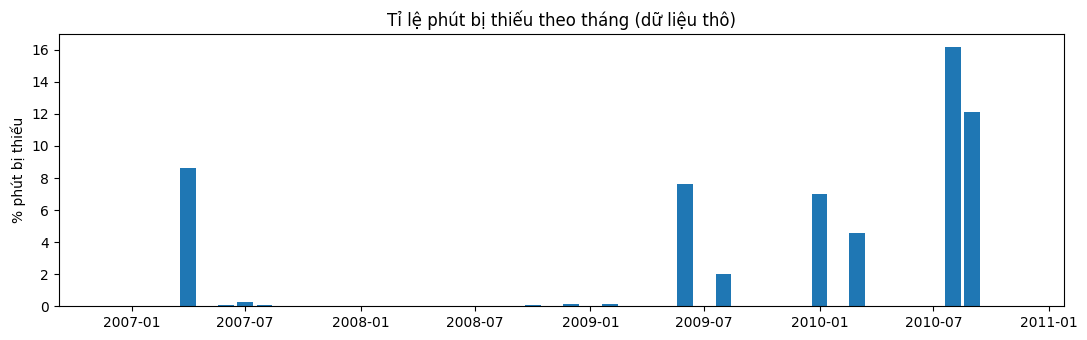

2026-11-14 01:41:13 | INFO | 3 tháng thiếu nhiều nhất: 08/2010 16.2%; 09/2010 12.1%; 04/2007 8.6%


In [9]:
mask = thieu.all(axis=1).to_numpy()
bd, dai = runs(mask)
khoang = pd.DataFrame({"bat_dau": ts.iloc[bd].to_numpy(), "so_phut": dai})
nhom = pd.cut(khoang["so_phut"], [0, 1, 10, 60, 120, np.inf],
              labels=["1 phút", "2–10 phút", "11–60 phút", "61–120 phút", "> 2 giờ"])
bang_khoang = khoang.groupby(nhom, observed=False)["so_phut"].agg(so_khoang="count", tong_phut="sum")
bang_khoang["ti_le_phut_thieu_%"] = (bang_khoang["tong_phut"] / mask.sum() * 100).round(1)
bang_khoang.to_csv(DIR_DATA / "eda_00_do_dai_khoang_thieu.csv", encoding="utf-8-sig")
display(bang_khoang)
log.info(f"{len(khoang)} khoảng thiếu, dài nhất {khoang['so_phut'].max()} phút ({khoang['so_phut'].max() / 60:.1f} giờ, "
         f"bắt đầu {khoang.loc[khoang['so_phut'].idxmax(), 'bat_dau']:%d/%m/%Y %H:%M})")

thieu_thang = pd.Series(mask, index=ts).resample("MS").mean() * 100
thieu_thang.round(3).rename("ti_le_thieu_%").to_csv(DIR_DATA / "eda_00_thieu_theo_thang.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(thieu_thang.index, thieu_thang.values, width=25)
ax.set_ylabel("% phút bị thiếu"); ax.set_title("Tỉ lệ phút bị thiếu theo tháng (dữ liệu thô)")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_thieu_theo_thang.png", dpi=150); plt.show()
top_thang = thieu_thang.sort_values(ascending=False).head(3)
log.info("3 tháng thiếu nhiều nhất: " + "; ".join(f"{d:%m/%Y} {v:.1f}%" for d, v in top_thang.items()))

n_dai = int((khoang["so_phut"] > 120).sum())
ghi_kho_khan("Thiếu thành từng khoảng liền nhau, có khoảng kéo dài nhiều ngày",
             f"{fmt(mask.sum())} phút thiếu ({mask.mean():.2%}) chia thành {len(khoang)} khoảng; {n_dai} khoảng dài hơn 2 giờ, "
             f"dài nhất {khoang['so_phut'].max() / 60:.1f} giờ; thiếu dồn vào vài tháng (cao nhất {top_thang.index[0]:%m/%Y}: {top_thang.iloc[0]:.1f}%)",
             "Không điền nhãn mục tiêu; đầu vào chỉ điền tiến tối đa 2 giờ và có cờ báo thiếu; khoảng dài để NaN",
             "01_cleaning, mục 4 và 8")

**Nhận xét:** 

Có 71 khoảng thiếu. Phần lớn là khoảng ngắn (38 khoảng chỉ 1 phút), nhưng 7 khoảng dài hơn 2 giờ lại chiếm 98,3% tổng số phút thiếu, dài nhất là 120,4 giờ bắt đầu từ 17/08/2010. Vì vậy không nên xử lý mọi khoảng thiếu giống nhau: ở 01_cleaning, khoảng thiếu ngắn (tối đa 2 giờ) được điền tiến cho đầu vào, còn khoảng dài để trống, và nhãn thì không điền.

## Khó khăn dữ liệu rút ra từ E0.2

In [10]:
bang_kk = pd.DataFrame(kho_khan[moc_kk:])
bang_kk.to_csv(DIR_DATA / f"eda_{MA_TN}_kho_khan.csv", encoding="utf-8-sig", index=False)
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)
log.info(f"{MA_TN}: {len(bang_kk)} khó khăn dữ liệu, lưu ở data/eda_data/eda_{MA_TN}_kho_khan.csv")

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
0,"Thiếu thành từng khoảng liền nhau, có khoảng kéo dài nhiều ngày","25.979 phút thiếu (1.25%) chia thành 71 khoảng; 7 khoảng dài hơn 2 giờ, dài nhất 120.4 giờ; thiếu dồn vào vài tháng (cao nhất 08/2010: 16.2%)",Không điền nhãn mục tiêu; đầu vào chỉ điền tiến tối đa 2 giờ và có cờ báo thiếu; khoảng dài để NaN,"01_cleaning, mục 4 và 8"


2026-11-14 01:41:13 | INFO | E0.2: 1 khó khăn dữ liệu, lưu ở data/eda_E0.2_kho_khan.csv


---
# Phần E0.3
> Nguồn: `notebooks/eda_notebooks/00_E0.3_phan_bo_va_quan_he_muc_phut_Han.ipynb`

In [11]:
MA_TN = "E0.3"
moc_kk = len(kho_khan)   # các khó khăn ghi từ đây trở đi thuộc E0.3

## 5. Phân bố của 7 biến ở mức phút
Thống kê mô tả, độ lệch và tỉ lệ giá trị 0. Hình vẽ trên mẫu ngẫu nhiên 200.000 phút (seed 42) cho nhanh; các con số trong bảng tính trên toàn bộ dữ liệu.

,count,mean,std,min,25%,50%,75%,max,skew,ti_le_bang_0_%,don_vi
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,0.0,kW
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,23.5,kVAR
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.0,V
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,0.0,A
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,91.7,Wh/phút
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,70.1,Wh/phút
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,41.6,Wh/phút


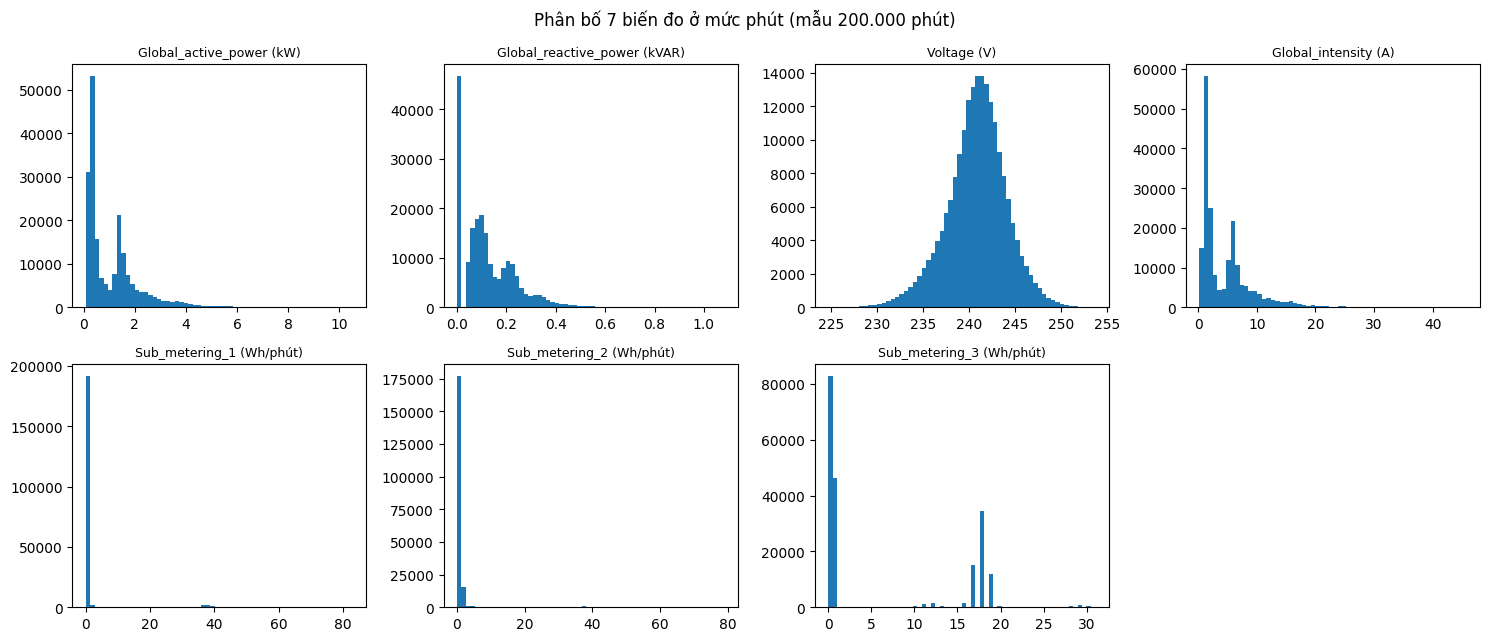

2026-11-14 01:41:16 | INFO | Độ lệch Global_active_power mức phút: 1.79


2026-11-14 01:41:16 | INFO | Tỉ lệ giá trị bằng 0: Sub_metering_1 91.7%; Sub_metering_2 70.1%; Sub_metering_3 41.6%


In [12]:
df = raw_str[COLS].replace({"?": np.nan, "": np.nan}).astype(float)
df.index = ts
del raw_str

tk = df.describe().T
tk["skew"] = df.skew()
tk["ti_le_bang_0_%"] = ((df == 0).sum() / df.notna().sum() * 100).round(1)
tk["don_vi"] = pd.Series(DON_VI)
tk.round(3).to_csv(DIR_DATA / "eda_00_thong_ke_phut.csv", encoding="utf-8-sig")
display(tk.round(3))

mau = df.dropna().sample(200_000, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, COLS):
    ax.hist(mau[c], bins=60)
    ax.set_title(f"{c} ({DON_VI[c]})", fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Phân bố 7 biến đo ở mức phút (mẫu 200.000 phút)")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_phan_bo_7_bien_phut.png", dpi=150); plt.show()

log.info(f"Độ lệch {TARGET} mức phút: {tk.loc[TARGET, 'skew']:.2f}")
log.info("Tỉ lệ giá trị bằng 0: " + "; ".join(f"{c} {tk.loc[c, 'ti_le_bang_0_%']}%" for c in SUB_COLS))
ghi_kho_khan("Phân bố lệch phải, công tơ phụ phần lớn bằng 0",
             f"{TARGET} skew = {tk.loc[TARGET, 'skew']:.2f}; Sub_metering_1 bằng 0 ở {tk.loc['Sub_metering_1', 'ti_le_bang_0_%']}% số phút, "
             f"Sub_metering_2 {tk.loc['Sub_metering_2', 'ti_le_bang_0_%']}%",
             "Ngoại lệ theo IQR chỉ đánh dấu, không xoá (đỉnh tiêu thụ là hành vi thật); với công tơ phụ IQR không dùng được vì đa số bằng 0",
             "01_cleaning, mục 6")
ghi_kho_khan("Các cột khác đơn vị và khác thang đo",
             "kW, kVAR, V, A, Wh/phút; Voltage quanh " + f"{tk.loc['Voltage', 'mean']:.0f} V trong khi công suất quanh {tk.loc[TARGET, 'mean']:.2f} kW",
             "Khi gộp theo giờ: lấy trung bình cho 4 biến điện, lấy tổng cho 3 công tơ phụ (Wh); Linear Regression dùng StandardScaler",
             "01_cleaning, mục 7; pipeline mô hình")

**Nhận xét:** 

Global_active_power có trung bình 1,092 kW nhưng trung vị chỉ 0,602 kW, độ lệch 1,79, nghĩa là phần lớn thời gian nhà dùng ít điện và chỉ thỉnh thoảng có lúc dùng rất nhiều. Ba công tơ phụ bằng 0 rất nhiều (91,7%, 70,1%, 41,6%) vì các thiết bị đó chỉ chạy lúc có người dùng. Các cột có đơn vị khác nhau (kW, V, A, Wh/phút) nên phải đổi về cùng đơn vị nếu muốn so sánh.


## 6. Các cột liên hệ với nhau thế nào?
- **Công suất và dòng điện:** về mặt vật lý, công suất ≈ điện áp × dòng điện × hệ số công suất. Nếu đúng vậy thì `Global_intensity` gần như là một bản sao của biến mục tiêu.
- **Điện năng cả hộ và công tơ phụ:** điện năng mỗi phút của cả hộ là `Global_active_power × 1000 / 60` (Wh). Phần còn lại sau khi trừ 3 công tơ phụ là điện năng của các thiết bị không có công tơ riêng; phần này không thể âm.

2026-11-14 01:41:16 | INFO | Tương quan Global_active_power – Global_intensity (mức phút): r = 0.9989


2026-11-14 01:41:16 | INFO | P / (V × I): trung vị 0.992; 5.75% số phút lớn hơn 1,05


2026-11-14 01:41:16 | INFO | Phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: 1.050 (0.051%), âm nhiều nhất -2.4 Wh


2026-11-14 01:41:16 | INFO | Tỉ trọng điện năng: Sub_metering_1 6.2%; Sub_metering_2 7.1%; Sub_metering_3 35.5%; còn lại 51.2%


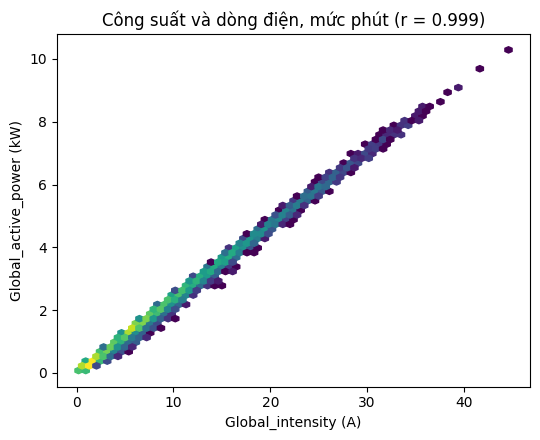

In [13]:
d = df.dropna()
r_I = d[TARGET].corr(d["Global_intensity"])
he_so = d[TARGET] * 1000 / (d["Voltage"] * d["Global_intensity"])
log.info(f"Tương quan {TARGET} – Global_intensity (mức phút): r = {r_I:.4f}")
log.info(f"P / (V × I): trung vị {he_so.median():.3f}; {(he_so > 1.05).mean():.2%} số phút lớn hơn 1,05")

dien_nang = d[TARGET] * 1000 / 60
con_lai = dien_nang - d[SUB_COLS].sum(axis=1)
am = int((con_lai < 0).sum())
ti_trong = (d[SUB_COLS].sum() / dien_nang.sum() * 100).round(1)
log.info(f"Phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: {fmt(am)} ({am / len(d):.3%}), âm nhiều nhất {con_lai.min():.1f} Wh")
log.info("Tỉ trọng điện năng: " + "; ".join(f"{c} {v}%" for c, v in ti_trong.items()) + f"; còn lại {100 - ti_trong.sum():.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
m = d.sample(100_000, random_state=SEED)
ax.hexbin(m["Global_intensity"], m[TARGET], gridsize=60, bins="log", mincnt=1)
ax.set_xlabel("Global_intensity (A)"); ax.set_ylabel("Global_active_power (kW)")
ax.set_title(f"Công suất và dòng điện, mức phút (r = {r_I:.3f})")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_cong_suat_va_dong_dien.png", dpi=150); plt.show()

ghi_kho_khan("Global_intensity gần như trùng với biến mục tiêu",
             f"r = {r_I:.3f} ở mức phút, vì công suất ≈ điện áp × dòng điện",
             "Không dùng Global_intensity của cùng giờ cần dự báo; chỉ dùng giá trị của các giờ trước (trễ) làm đặc trưng",
             "03_features")
ghi_kho_khan("Tổng công tơ phụ đôi khi lớn hơn điện năng cả hộ",
             f"{fmt(am)} phút ({am / len(d):.3%}), lệch nhiều nhất {abs(con_lai.min()):.1f} Wh",
             "Chỉ ghi nhận, không sửa (sai số làm tròn và sai số đo của công tơ)",
             "01_cleaning, mục 5")

**Nhận xét:** 

Công suất và dòng điện tương quan gần như tuyệt đối (r = 0,9989), vì công suất ≈ điện áp × dòng điện. Do đó không nên dùng Global_intensity của cùng thời điểm để dự báo công suất, vì như vậy là biết trước đáp án. Ba công tơ phụ chỉ đo được một phần điện năng (6,2%, 7,1% và 35,5%), 51,2% còn lại là các thiết bị không có công tơ riêng.

## 7. Mức phút hay mức giờ?
So sánh một ngày đủ dữ liệu ở mức phút với trung bình theo giờ của cùng ngày.

2026-11-14 01:41:16 | INFO | Ngày minh hoạ 01/01/2008: độ lệch chuẩn mức phút 1.026 kW, mức giờ 0.803 kW


2026-11-14 01:41:16 | INFO | Thay đổi trung bình giữa 2 phút liên tiếp: 0.084 kW; 1.93% số lần đổi hơn 1 kW chỉ trong 1 phút


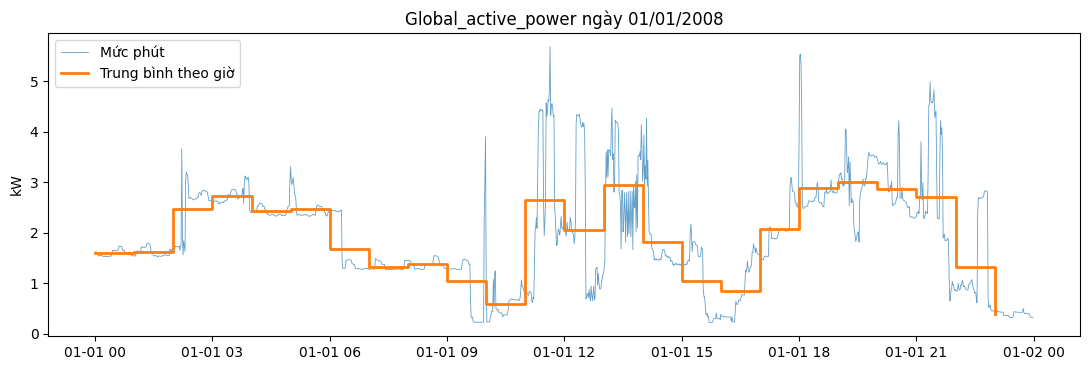

In [14]:
ngay_du = d[TARGET].resample("D").count()
ngay = ngay_du[ngay_du == 1440].index[ngay_du[ngay_du == 1440].index >= "2008-01-01"][0]
mot_ngay = df.loc[f"{ngay:%Y-%m-%d}", TARGET]
theo_gio = mot_ngay.resample("h").mean()
log.info(f"Ngày minh hoạ {ngay:%d/%m/%Y}: độ lệch chuẩn mức phút {mot_ngay.std():.3f} kW, mức giờ {theo_gio.std():.3f} kW")
bien_dong = df[TARGET].diff().abs()
log.info(f"Thay đổi trung bình giữa 2 phút liên tiếp: {bien_dong.mean():.3f} kW; "
         f"{(bien_dong > 1).mean():.2%} số lần đổi hơn 1 kW chỉ trong 1 phút")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(mot_ngay.index, mot_ngay.values, lw=0.6, alpha=0.7, label="Mức phút")
ax.step(theo_gio.index, theo_gio.values, where="post", lw=2, label="Trung bình theo giờ")
ax.set_ylabel("kW"); ax.set_title(f"Global_active_power ngày {ngay:%d/%m/%Y}"); ax.legend()
fig.tight_layout(); fig.savefig(DIR_FIG / "00_mot_ngay_phut_va_gio.png", dpi=150); plt.show()

ghi_kho_khan("Dữ liệu mức phút rất nhiễu",
             f"Trung bình mỗi phút công suất đổi {bien_dong.mean():.3f} kW; {(bien_dong > 1).mean():.2%} số lần đổi hơn 1 kW trong 1 phút",
             "Gộp thành trung bình theo giờ và dự báo giờ kế tiếp (giờ hợp lệ khi có ít nhất 30 phút đo được)",
             "01_cleaning, mục 7")

**Nhận xét:** 

Dữ liệu mức phút dao động mạnh: trong ngày 01/01/2008, độ lệch chuẩn mức phút là 1,026 kW, còn mức giờ là 0,803 kW, và có 1,93% số lần công suất thay đổi hơn 1 kW chỉ trong 1 phút. Gộp theo giờ giúp dữ liệu bớt nhiễu, đây là lý do nhóm chọn dự báo theo giờ.

## Khó khăn dữ liệu rút ra từ E0.3

In [15]:
bang_kk = pd.DataFrame(kho_khan[moc_kk:])
bang_kk.to_csv(DIR_DATA / f"eda_{MA_TN}_kho_khan.csv", encoding="utf-8-sig", index=False)
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)
log.info(f"{MA_TN}: {len(bang_kk)} khó khăn dữ liệu, lưu ở data/eda_data/eda_{MA_TN}_kho_khan.csv")

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
0,"Phân bố lệch phải, công tơ phụ phần lớn bằng 0","Global_active_power skew = 1.79; Sub_metering_1 bằng 0 ở 91.7% số phút, Sub_metering_2 70.1%","Ngoại lệ theo IQR chỉ đánh dấu, không xoá (đỉnh tiêu thụ là hành vi thật); với công tơ phụ IQR không dùng được vì đa số bằng 0","01_cleaning, mục 6"
1,Các cột khác đơn vị và khác thang đo,"kW, kVAR, V, A, Wh/phút; Voltage quanh 241 V trong khi công suất quanh 1.09 kW","Khi gộp theo giờ: lấy trung bình cho 4 biến điện, lấy tổng cho 3 công tơ phụ (Wh); Linear Regression dùng StandardScaler","01_cleaning, mục 7; pipeline mô hình"
2,Global_intensity gần như trùng với biến mục tiêu,"r = 0.999 ở mức phút, vì công suất ≈ điện áp × dòng điện",Không dùng Global_intensity của cùng giờ cần dự báo; chỉ dùng giá trị của các giờ trước (trễ) làm đặc trưng,03_features
3,Tổng công tơ phụ đôi khi lớn hơn điện năng cả hộ,"1.050 phút (0.051%), lệch nhiều nhất 2.4 Wh","Chỉ ghi nhận, không sửa (sai số làm tròn và sai số đo của công tơ)","01_cleaning, mục 5"
4,Dữ liệu mức phút rất nhiễu,Trung bình mỗi phút công suất đổi 0.084 kW; 1.93% số lần đổi hơn 1 kW trong 1 phút,Gộp thành trung bình theo giờ và dự báo giờ kế tiếp (giờ hợp lệ khi có ít nhất 30 phút đo được),"01_cleaning, mục 7"


2026-11-14 01:41:17 | INFO | E0.3: 5 khó khăn dữ liệu, lưu ở data/eda_E0.3_kho_khan.csv


---
# Phần E0.4
> Nguồn: `notebooks/eda_notebooks/02_E0.4_phan_bo_cong_suat_theo_gio_Han.ipynb`

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda_notebooks/
FILE = ROOT / "data" / "processed" / "hourly_clean.csv"
DIR_DATA = ROOT / "data" / "eda_data"
DIR_FIG = ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "svg.fonttype": "none"})

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
VAR_RQ2 = ["Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]

DOW_LABEL = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
PERIOD_LABEL = {1: "Năm 1\n12/2006–11/2007", 2: "Năm 2\n12/2007–11/2008",
                3: "Năm 3\n12/2008–11/2009", 4: "Năm 4\n12/2009–11/2010"}

def season_of(m):
    """Mùa theo khí hậu Pháp (bắc bán cầu): Đông 12-2, Xuân 3-5, Hè 6-8, Thu 9-11."""
    if m in (12, 1, 2): return "Đông"
    if m in (3, 4, 5): return "Xuân"
    if m in (6, 7, 8): return "Hè"
    return "Thu"

def vn(x, d=3):
    """Số kiểu Việt Nam: dấu phẩy thập phân."""
    return f"{x:.{d}f}".replace(".", ",")

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def strength(r):
    a = abs(r)
    if a >= 0.7: return "mạnh"
    if a >= 0.4: return "trung bình"
    if a >= 0.2: return "yếu"
    return "rất yếu"

def save_fig(name):
    plt.savefig(DIR_FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(DIR_FIG / f"{name}.svg", bbox_inches="tight")

notes = []   # các câu gợi ý nhận xét (số liệu tự điền)
def add_note(tag, text):
    notes.append(f"- **[{tag}]** {text}")

In [17]:
raw = pd.read_csv(FILE, parse_dates=["datetime"], index_col="datetime")
assert (raw.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), "Trục giờ không liên tục"

df = raw[COLS].copy()                       # chỉ 7 cột gốc, không dùng *_ffill
df["hour"] = df.index.hour
df["dow"] = df.index.dayofweek              # 0 = thứ 2 ... 6 = chủ nhật
df["is_weekend"] = df["dow"] >= 5
df["month"] = df.index.month
df["season"] = df["month"].map(season_of)
# Năm vận hành: tháng 12 đến tháng 11 năm sau (khớp với khoảng dữ liệu 12/2006 đến 11/2010)
df["period"] = np.asarray(((df.index.year * 12 + df.index.month) - (2006 * 12 + 12)) // 12 + 1)

n_all = len(df)
n_valid = int(df[TARGET].notna().sum())
print(f"Tổng số giờ: {fmt(n_all)} | Giờ có số đo thật: {fmt(n_valid)} | Giờ thiếu (bỏ qua): {fmt(n_all - n_valid)}")
print("Khoảng thời gian:", df.index[0], "->", df.index[-1])
print("Số giờ có số đo theo mùa:\n", df.groupby("season")[TARGET].count().reindex(SEASON_ORDER))
df.head()

Tổng số giờ: 34.588 | Giờ có số đo thật: 34.157 | Giờ thiếu (bỏ qua): 431
Khoảng thời gian: 2006-12-16 17:00:00 -> 2010-11-26 20:00:00
Số giờ có số đo theo mùa:
 season
Xuân    8736
Hè      8639
Thu     8549
Đông    8233
Name: Global_active_power, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,dow,is_weekend,month,season,period
datetime,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,17,5,True,12,Đông,1
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,18,5,True,12,Đông,1
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,19,5,True,12,Đông,1
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,20,5,True,12,Đông,1
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,21,5,True,12,Đông,1


In [18]:
MA_TN = "E0.4"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.4

## 2. Phân bố của biến mục tiêu `Global_active_power`
Xem hình dạng phân bố trước khi đi vào quy luật theo thời gian.

count    34157.0000
mean         1.0916
std          0.8977
min          0.1240
25%          0.3419
50%          0.8026
75%          1.5793
max          6.5605
Name: Global_active_power, dtype: float64
Độ lệch (skewness): 1.298


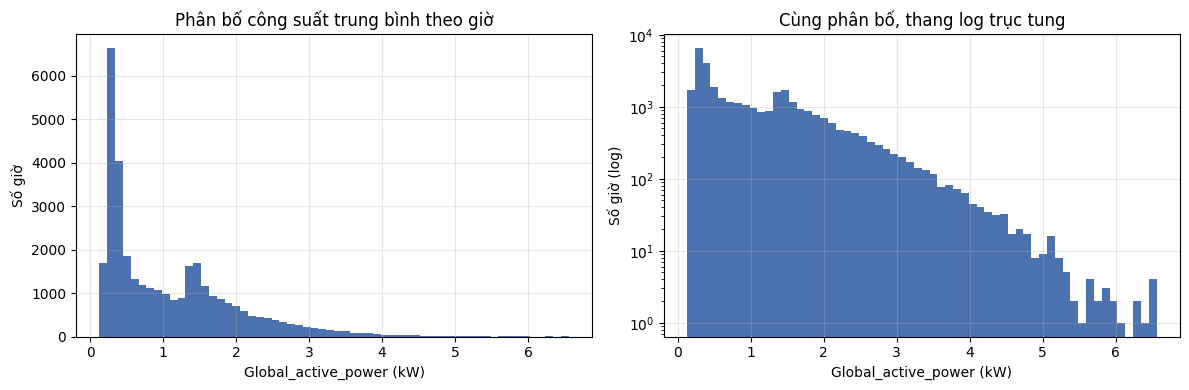

In [19]:
s = df[TARGET].dropna()
desc = s.describe()
skew = s.skew()
print(desc.round(4))
print("Độ lệch (skewness):", round(skew, 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(s, bins=60, color="#4C72B0")
ax[0].set_title("Phân bố công suất trung bình theo giờ")
ax[0].set_xlabel("Global_active_power (kW)"); ax[0].set_ylabel("Số giờ")
ax[1].hist(s, bins=60, color="#4C72B0", log=True)
ax[1].set_title("Cùng phân bố, thang log trục tung")
ax[1].set_xlabel("Global_active_power (kW)"); ax[1].set_ylabel("Số giờ (log)")
plt.tight_layout()
save_fig("02_phan_bo_cong_suat")
plt.show()

add_note("Phân bố", f"Công suất trung bình theo giờ có trung bình {vn(s.mean())} kW, trung vị {vn(s.median())} kW, độ lệch chuẩn {vn(s.std())} kW; "
         f"giá trị nhỏ nhất {vn(s.min())} kW và lớn nhất {vn(s.max())} kW. Độ lệch (skewness) bằng {vn(skew, 2)}, "
         f"{'phân bố lệch phải: phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ tiêu thụ cao' if skew > 0.5 else 'phân bố không lệch rõ rệt'}.")

**Nhận xét:** Phân bố công suất theo giờ lệch phải rõ (skewness 1,30): trung bình 1,092 kW lớn hơn trung vị 0,803 kW. Phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ lên tới 6,561 kW. Vì vậy sai số của mô hình dễ bị kéo lên bởi các đỉnh hiếm này.

## Gợi ý nhận xét E0.4 (số tự điền)

In [20]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 01:41:17 | INFO | Gợi ý nhận xét E0.4 (số tự điền), lưu ở data/eda_E0.4_goi_y_nhan_xet.md:
- **[Phân bố]** Công suất trung bình theo giờ có trung bình 1,092 kW, trung vị 0,803 kW, độ lệch chuẩn 0,898 kW; giá trị nhỏ nhất 0,124 kW và lớn nhất 6,561 kW. Độ lệch (skewness) bằng 1,30, phân bố lệch phải: phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ tiêu thụ cao.


---
# Phần E0.5
> Nguồn: `notebooks/eda_notebooks/02_E0.5_rq1_theo_gio_va_thu_Han.ipynb`

In [21]:
MA_TN = "E0.5"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.5

## 3. RQ1 (a): Theo giờ trong ngày, ngày thường và cuối tuần
- Hình trái: công suất trung bình theo từng giờ trong ngày, dải màu là khoảng từ phân vị 25% đến 75%.
- Hình phải: so sánh ngày thường (T2 đến T6) và cuối tuần (T7, CN).

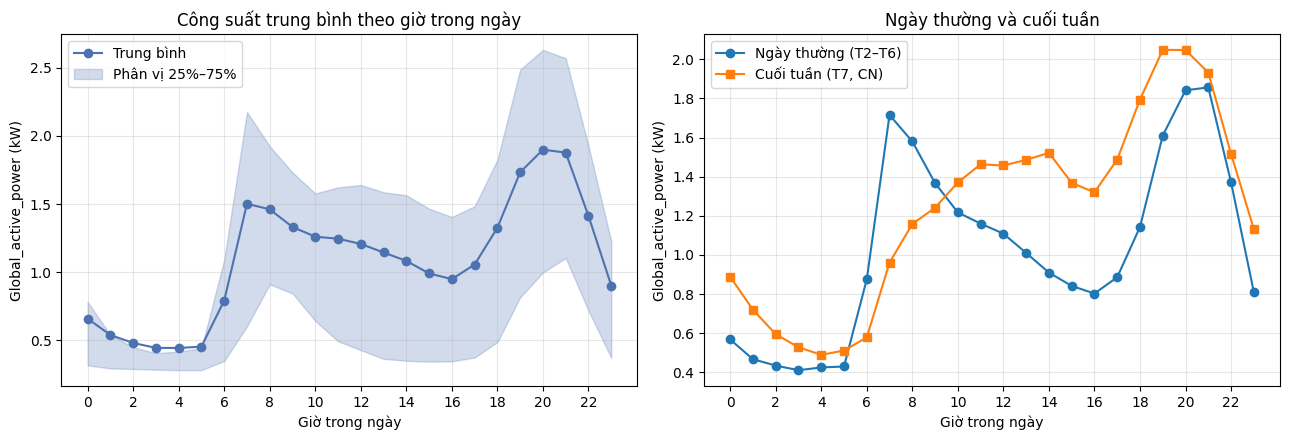

,tat_ca,q25,q75,do_lech_chuan,so_gio_do,ngay_thuong,cuoi_tuan
hour,,,,,,,
0,0.659,0.317,0.782,0.618,1425,0.569,0.888
1,0.539,0.294,0.539,0.501,1424,0.468,0.721
2,0.481,0.290,0.450,0.410,1424,0.435,0.596
3,0.445,0.285,0.406,0.357,1424,0.412,0.529
4,0.444,0.281,0.417,0.344,1422,0.426,0.490
5,0.454,0.282,0.443,0.354,1421,0.431,0.512
6,0.792,0.348,1.092,0.513,1421,0.875,0.579
7,1.502,0.602,2.175,0.894,1421,1.715,0.961
8,1.461,0.911,1.924,0.753,1422,1.580,1.158


In [22]:
g = df.groupby("hour")[TARGET]
prof = pd.DataFrame({"tat_ca": g.mean(), "q25": g.quantile(0.25), "q75": g.quantile(0.75),
                     "do_lech_chuan": g.std(), "so_gio_do": g.count()})
wk = (df.groupby(["hour", "is_weekend"])[TARGET].mean().unstack()
        .rename(columns={False: "ngay_thuong", True: "cuoi_tuan"}))
prof = prof.join(wk)
prof.round(4).to_csv(DIR_DATA / "eda_rq1_theo_gio.csv", index_label="gio")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(prof.index, prof["tat_ca"], marker="o", color="#4C72B0", label="Trung bình")
ax[0].fill_between(prof.index, prof["q25"], prof["q75"], alpha=0.25, color="#4C72B0", label="Phân vị 25%–75%")
ax[0].set_title("Công suất trung bình theo giờ trong ngày")
ax[0].set_xlabel("Giờ trong ngày"); ax[0].set_ylabel("Global_active_power (kW)")
ax[0].set_xticks(range(0, 24, 2)); ax[0].legend()
ax[1].plot(prof.index, prof["ngay_thuong"], marker="o", label="Ngày thường (T2–T6)")
ax[1].plot(prof.index, prof["cuoi_tuan"], marker="s", label="Cuối tuần (T7, CN)")
ax[1].set_title("Ngày thường và cuối tuần")
ax[1].set_xlabel("Giờ trong ngày"); ax[1].set_ylabel("Global_active_power (kW)")
ax[1].set_xticks(range(0, 24, 2)); ax[1].legend()
plt.tight_layout()
save_fig("02_rq1_theo_gio")
plt.show()
prof.round(3)

In [23]:
pk_h, tr_h = int(prof["tat_ca"].idxmax()), int(prof["tat_ca"].idxmin())
mor_h = int(prof.loc[5:12, "tat_ca"].idxmax())     # đỉnh trong khung 5h-12h
eve_h = int(prof.loc[17:23, "tat_ca"].idxmax())    # đỉnh trong khung 17h-23h
add_note("RQ1-giờ", f"Công suất trung bình cao nhất lúc {pk_h}h ({vn(prof.loc[pk_h, 'tat_ca'])} kW) và thấp nhất lúc {tr_h}h "
         f"({vn(prof.loc[tr_h, 'tat_ca'])} kW), gấp {vn(prof.loc[pk_h, 'tat_ca'] / prof.loc[tr_h, 'tat_ca'], 1)} lần. "
         f"Đỉnh trong khung 5h–12h là lúc {mor_h}h ({vn(prof.loc[mor_h, 'tat_ca'])} kW); đỉnh trong khung 17h–23h là lúc {eve_h}h ({vn(prof.loc[eve_h, 'tat_ca'])} kW).")

wd_mean = df.loc[~df["is_weekend"], TARGET].mean()
we_mean = df.loc[df["is_weekend"], TARGET].mean()
diff_pct = (we_mean / wd_mean - 1) * 100
add_note("RQ1-cuối tuần", f"Trung bình cả ngày: ngày thường {vn(wd_mean)} kW, cuối tuần {vn(we_mean)} kW; cuối tuần "
         f"{'cao hơn' if diff_pct > 0 else 'thấp hơn'} ngày thường {vn(abs(diff_pct), 1)}%.")
dh = prof["cuoi_tuan"] - prof["ngay_thuong"]
h_max = int(dh.abs().idxmax())
add_note("RQ1-cuối tuần", f"Chênh lệch giữa cuối tuần và ngày thường lớn nhất lúc {h_max}h: cuối tuần "
         f"{'cao hơn' if dh[h_max] > 0 else 'thấp hơn'} {vn(abs(dh[h_max]))} kW "
         f"({vn(prof.loc[h_max, 'cuoi_tuan'])} so với {vn(prof.loc[h_max, 'ngay_thuong'])} kW).")

**Nhận xét:** Công suất cao nhất lúc 20h (1,899 kW), thấp nhất lúc 4h (0,444 kW), gấp 4,3 lần; có hai đỉnh trong ngày là 7h (1,502 kW) và 20h. Cuối tuần trung bình 1,234 kW, cao hơn ngày thường (1,035 kW) 19,2%; chênh lệch rõ nhất lúc 7h (ngày thường 1,715 kW, cuối tuần 0,961 kW) vì sáng cuối tuần không có giờ cao điểm đi làm, đi học. Giờ trong ngày là yếu tố ảnh hưởng rõ nhất nên cần đưa đặc trưng giờ vào mô hình.

## 4. RQ1 (b): Theo thứ trong tuần và bản đồ nhiệt giờ × thứ

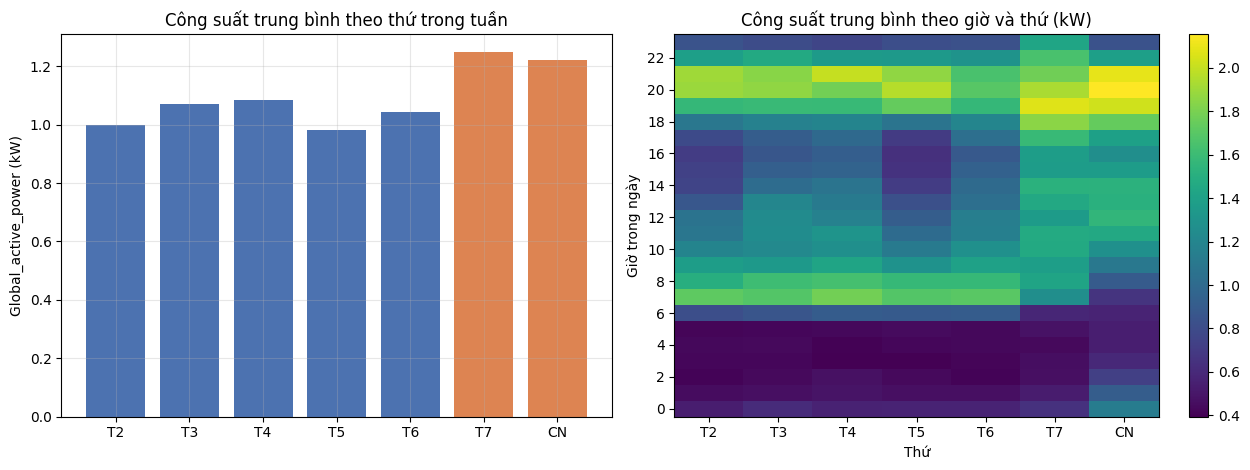

,mean,std,count
T2,0.999,0.812,4898
T3,1.070,0.861,4913
T4,1.083,0.855,4895
T5,0.982,0.824,4886
T6,1.043,0.820,4917
T7,1.248,1.022,4814
CN,1.220,1.029,4834


In [24]:
d = df.groupby("dow")[TARGET].agg(["mean", "std", "count"])
d.index = DOW_LABEL
d.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thu.csv", index_label="thu")

pv = df.pivot_table(index="hour", columns="dow", values=TARGET, aggfunc="mean")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
colors = ["#4C72B0"] * 5 + ["#DD8452"] * 2
ax[0].bar(d.index, d["mean"], color=colors)
ax[0].set_title("Công suất trung bình theo thứ trong tuần")
ax[0].set_ylabel("Global_active_power (kW)")
im = ax[1].imshow(pv.values, aspect="auto", origin="lower", cmap="viridis")
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(DOW_LABEL)
ax[1].set_yticks(range(0, 24, 2)); ax[1].set_yticklabels(range(0, 24, 2))
ax[1].set_title("Công suất trung bình theo giờ và thứ (kW)")
ax[1].set_xlabel("Thứ"); ax[1].set_ylabel("Giờ trong ngày"); ax[1].grid(False)
plt.colorbar(im, ax=ax[1])
plt.tight_layout()
save_fig("02_rq1_theo_thu_heatmap")
plt.show()
d.round(3)

In [25]:
best_d, worst_d = d["mean"].idxmax(), d["mean"].idxmin()
add_note("RQ1-thứ", f"Thứ có công suất trung bình cao nhất là {best_d} ({vn(d.loc[best_d, 'mean'])} kW), thấp nhất là {worst_d} ({vn(d.loc[worst_d, 'mean'])} kW); "
         f"chênh nhau {vn((d.loc[best_d, 'mean'] / d.loc[worst_d, 'mean'] - 1) * 100, 1)}%.")

**Nhận xét:** Thứ Bảy có công suất trung bình cao nhất (1,248 kW), thứ Năm thấp nhất (0,982 kW), chênh nhau 27,2%. Bản đồ nhiệt cho thấy sáng ngày thường có đỉnh rõ lúc 7h, còn cuối tuần tiêu thụ trải đều hơn từ trưa đến chiều. Đây là cơ sở để dùng đặc trưng thứ và cờ cuối tuần.

## Gợi ý nhận xét E0.5 (số tự điền)

In [26]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 01:41:18 | INFO | Gợi ý nhận xét E0.5 (số tự điền), lưu ở data/eda_E0.5_goi_y_nhan_xet.md:
- **[RQ1-giờ]** Công suất trung bình cao nhất lúc 20h (1,899 kW) và thấp nhất lúc 4h (0,444 kW), gấp 4,3 lần. Đỉnh trong khung 5h–12h là lúc 7h (1,502 kW); đỉnh trong khung 17h–23h là lúc 20h (1,899 kW).
- **[RQ1-cuối tuần]** Trung bình cả ngày: ngày thường 1,035 kW, cuối tuần 1,234 kW; cuối tuần cao hơn ngày thường 19,2%.
- **[RQ1-cuối tuần]** Chênh lệch giữa cuối tuần và ngày thường lớn nhất lúc 7h: cuối tuần thấp hơn 0,754 kW (0,961 so với 1,715 kW).
- **[RQ1-thứ]** Thứ có công suất trung bình cao nhất là T7 (1,248 kW), thấp nhất là T5 (0,982 kW); chênh nhau 27,2%.


---
# Phần E0.6
> Nguồn: `notebooks/eda_notebooks/02_E0.6_rq1_theo_thang_mua_xu_huong_Han.ipynb`

In [27]:
MA_TN = "E0.6"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.6

## 5. RQ1 (c): Theo tháng và mùa
Mùa theo khí hậu Pháp (Đông: 12–2, Xuân: 3–5, Hè: 6–8, Thu: 9–11). Mỗi tháng dương lịch xuất hiện đúng 4 lần trong dữ liệu (12/2006–11/2010) nên trung bình theo tháng và mùa cân bằng giữa các năm.

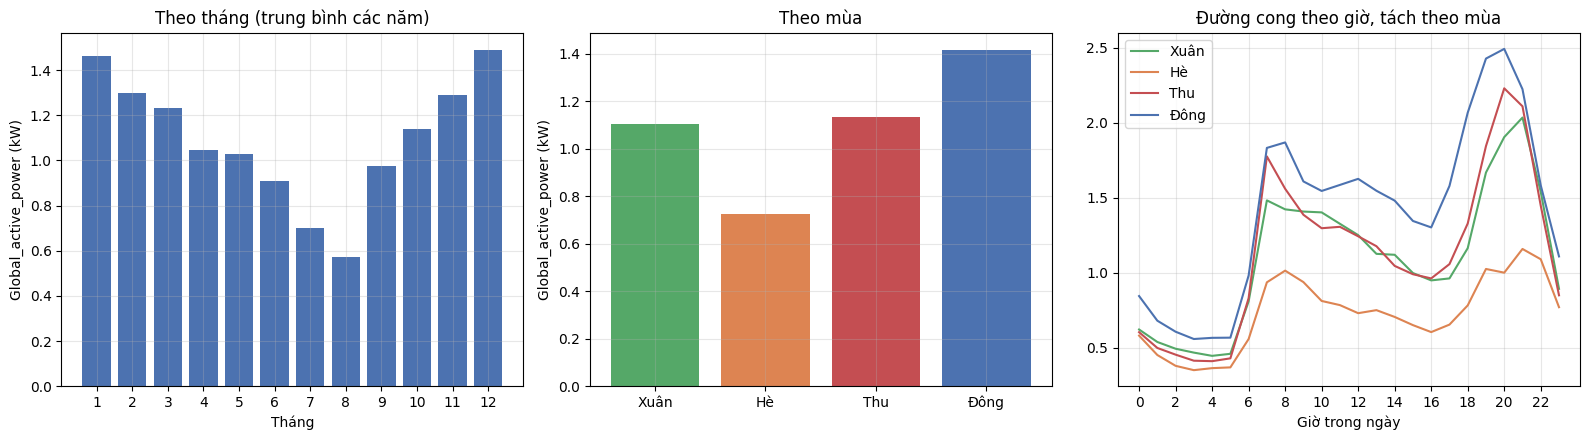

,mean,std,count,nhom
Tháng 1,1.462,1.045,2924,thang
Tháng 2,1.300,1.009,2711,thang
Tháng 3,1.231,0.929,2942,thang
Tháng 4,1.047,0.819,2818,thang
Tháng 5,1.030,0.757,2976,thang
Tháng 6,0.909,0.705,2824,thang
Tháng 7,0.700,0.567,2974,thang
Tháng 8,0.573,0.591,2841,thang
Tháng 9,0.976,0.776,2793,thang
Tháng 10,1.137,0.891,2975,thang


In [28]:
mth = df.groupby("month")[TARGET].agg(["mean", "std", "count"])
ses = df.groupby("season")[TARGET].agg(["mean", "std", "count"]).reindex(SEASON_ORDER)
prof_season = df.groupby(["hour", "season"])[TARGET].mean().unstack()[SEASON_ORDER]

tbl = pd.concat([
    mth.rename(index=lambda m: f"Tháng {m}").assign(nhom="thang"),
    ses.rename(index=lambda s_: f"Mùa {s_}").assign(nhom="mua"),
])
tbl.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thang_mua.csv", index_label="ten")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].bar(mth.index, mth["mean"], color="#4C72B0")
ax[0].set_xticks(range(1, 13)); ax[0].set_title("Theo tháng (trung bình các năm)")
ax[0].set_xlabel("Tháng"); ax[0].set_ylabel("Global_active_power (kW)")
ax[1].bar(ses.index, ses["mean"], color=["#55A868", "#DD8452", "#C44E52", "#4C72B0"])
ax[1].set_title("Theo mùa"); ax[1].set_ylabel("Global_active_power (kW)")
for c, col in zip(SEASON_ORDER, ["#55A868", "#DD8452", "#C44E52", "#4C72B0"]):
    ax[2].plot(prof_season.index, prof_season[c], label=c, color=col)
ax[2].set_title("Đường cong theo giờ, tách theo mùa")
ax[2].set_xlabel("Giờ trong ngày"); ax[2].set_xticks(range(0, 24, 2)); ax[2].legend()
plt.tight_layout()
save_fig("02_rq1_theo_thang_mua")
plt.show()
tbl.round(3)

In [29]:
hi_m, lo_m = int(mth["mean"].idxmax()), int(mth["mean"].idxmin())
add_note("RQ1-mùa", f"Tháng có công suất trung bình cao nhất là tháng {hi_m} ({vn(mth.loc[hi_m, 'mean'])} kW), thấp nhất là tháng {lo_m} ({vn(mth.loc[lo_m, 'mean'])} kW).")
hi_s, lo_s = ses["mean"].idxmax(), ses["mean"].idxmin()
add_note("RQ1-mùa", "Trung bình theo mùa: " + "; ".join(f"{k} {vn(v)} kW" for k, v in ses["mean"].items()) +
         f". Mùa cao nhất là {hi_s}, thấp nhất là {lo_s}, chênh nhau {vn((ses.loc[hi_s, 'mean'] / ses.loc[lo_s, 'mean'] - 1) * 100, 1)}%.")
dh_win = prof_season["Đông"] - prof_season["Hè"]
add_note("RQ1-mùa", f"Giữa mùa Đông và mùa Hè, chênh lệch theo giờ lớn nhất lúc {int(dh_win.abs().idxmax())}h "
         f"(Đông {vn(prof_season.loc[int(dh_win.abs().idxmax()), 'Đông'])} kW, Hè {vn(prof_season.loc[int(dh_win.abs().idxmax()), 'Hè'])} kW).")

**Nhận xét:** Tháng 12 cao nhất (1,490 kW), tháng 8 thấp nhất (0,573 kW). Theo mùa: Đông 1,418 kW; Thu 1,135; Xuân 1,103; Hè 0,727, tức mùa Đông cao hơn mùa Hè khoảng 95%. Chênh lệch lớn nhất lúc 20h (Đông 2,493 kW, Hè 1,000 kW), nên cần đặc trưng tháng (sin/cos) để mô hình nắm được chu kỳ năm.

## 6. RQ1 (d): Xu hướng dài hạn
- Chuỗi trung bình theo tháng. Vòng tròn đỏ rỗng là tháng có ít hơn 90% số giờ đo được (do các khoảng thiếu), nên giá trị trung bình kém tin cậy hơn.
- Trung bình theo "năm vận hành" (tháng 12 đến tháng 11). Lưu ý tháng 12/2006 chỉ bắt đầu từ ngày 16 và tháng 11/2010 kết thúc ngày 26.

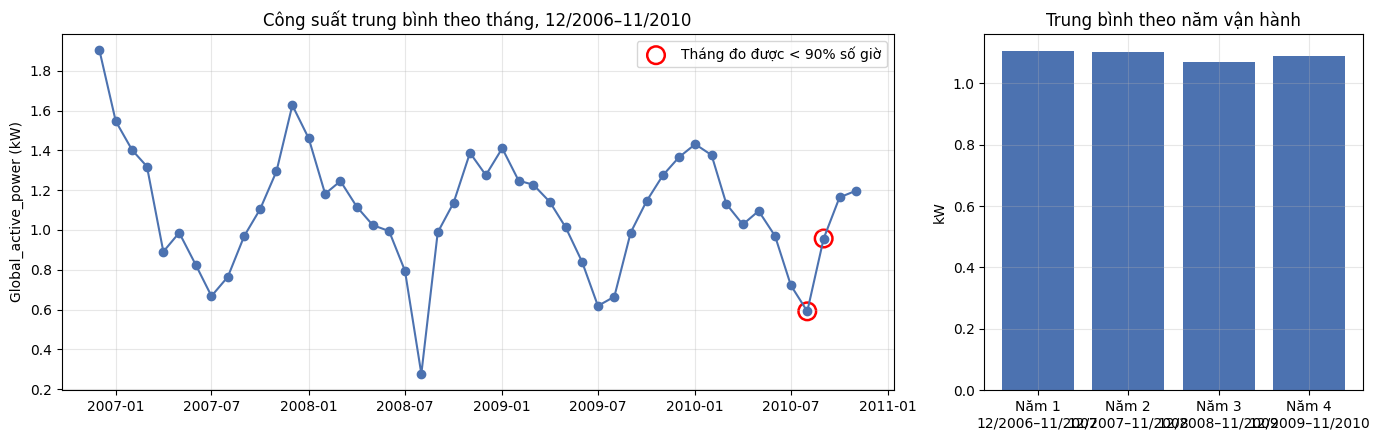

Số tháng đo được < 90% số giờ: 2


,mean,std,count,so_voi_nam_1_%
period,,,,
1,1.106,0.994,8318,0.000
2,1.102,0.944,8783,-0.379
3,1.071,0.838,8688,-3.177
4,1.088,0.802,8368,-1.633


In [30]:
mon = df[TARGET].resample("MS").agg(["mean", "count"])
mon["so_gio_luoi"] = df[TARGET].resample("MS").size()
mon["ty_le_do_duoc"] = mon["count"] / mon["so_gio_luoi"]
low_cov = mon[mon["ty_le_do_duoc"] < 0.90]

per = df.groupby("period")[TARGET].agg(["mean", "std", "count"])
per["so_voi_nam_1_%"] = (per["mean"] / per.loc[1, "mean"] - 1) * 100
per.round(4).to_csv(DIR_DATA / "eda_rq1_theo_nam.csv", index_label="nam_van_hanh")
mon.round(4).to_csv(DIR_DATA / "eda_rq1_theo_thang_chuoi.csv", index_label="thang")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(mon.index, mon["mean"], marker="o", color="#4C72B0")
ax[0].scatter(low_cov.index, low_cov["mean"], s=160, facecolors="none", edgecolors="red", linewidths=1.8,
              label="Tháng đo được < 90% số giờ")
ax[0].set_title("Công suất trung bình theo tháng, 12/2006–11/2010")
ax[0].set_ylabel("Global_active_power (kW)"); ax[0].legend()
ax[1].bar([PERIOD_LABEL[i] for i in per.index], per["mean"], color="#4C72B0")
ax[1].set_title("Trung bình theo năm vận hành"); ax[1].set_ylabel("kW")
plt.tight_layout()
save_fig("02_rq1_xu_huong")
plt.show()
print("Số tháng đo được < 90% số giờ:", len(low_cov))
per.round(3)

In [31]:
add_note("RQ1-xu hướng", "Trung bình theo năm vận hành (tháng 12 đến tháng 11): " +
         "; ".join(f"năm {i} {vn(r['mean'])} kW" for i, r in per.iterrows()) +
         f". Năm 4 so với năm 1: {'cao hơn' if per.loc[4, 'so_voi_nam_1_%'] > 0 else 'thấp hơn'} {vn(abs(per.loc[4, 'so_voi_nam_1_%']), 1)}%.")
add_note("RQ1-xu hướng", f"Có {len(low_cov)} tháng đo được dưới 90% số giờ (cần thận trọng khi đọc giá trị các tháng này): "
         + (", ".join(m.strftime("%m/%Y") for m in low_cov.index) if len(low_cov) else "không có") + ".")

**Nhận xét:** Trung bình theo năm vận hành gần như không đổi: 1,106; 1,102; 1,071; 1,088 kW; năm 4 thấp hơn năm 1 chỉ 1,6%. Không thấy xu hướng dài hạn rõ rệt, nên chia Train và Test theo thời gian không làm lệch mức tiêu thụ giữa hai tập. Hai tháng 08/2010 và 09/2010 đo được dưới 90% số giờ nên cần đọc thận trọng.

## Gợi ý nhận xét E0.6 (số tự điền)

In [32]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 01:41:18 | INFO | Gợi ý nhận xét E0.6 (số tự điền), lưu ở data/eda_E0.6_goi_y_nhan_xet.md:
- **[RQ1-mùa]** Tháng có công suất trung bình cao nhất là tháng 12 (1,490 kW), thấp nhất là tháng 8 (0,573 kW).
- **[RQ1-mùa]** Trung bình theo mùa: Xuân 1,103 kW; Hè 0,727 kW; Thu 1,135 kW; Đông 1,418 kW. Mùa cao nhất là Đông, thấp nhất là Hè, chênh nhau 95,1%.
- **[RQ1-mùa]** Giữa mùa Đông và mùa Hè, chênh lệch theo giờ lớn nhất lúc 20h (Đông 2,493 kW, Hè 1,000 kW).
- **[RQ1-xu hướng]** Trung bình theo năm vận hành (tháng 12 đến tháng 11): năm 1 1,106 kW; năm 2 1,102 kW; năm 3 1,071 kW; năm 4 1,088 kW. Năm 4 so với năm 1: thấp hơn 1,6%.
- **[RQ1-xu hướng]** Có 2 tháng đo được dưới 90% số giờ (cần thận trọng khi đọc giá trị các tháng này): 08/2010, 09/2010.


---
# Phần E0.7
> Nguồn: `notebooks/eda_notebooks/02_E0.7_rq1_chu_ky_va_cong_to_phu_Han.ipynb`

In [33]:
MA_TN = "E0.7"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.7

## 7. RQ1 (e): Chu kỳ của chuỗi (tự tương quan)
Tự tương quan (ACF) của `Global_active_power` theo độ trễ 1 đến 200 giờ. Nếu chuỗi có chu kỳ ngày và tuần thì ACF có đỉnh tại bội số của 24 giờ và tại 168 giờ. Đây là bằng chứng mô tả cho việc chọn đặc trưng trễ 24h và 168h ở bước sau (các lag này đã nêu trong Proposal, chưa dựa vào Test).

Các đỉnh ACF cao nhất (độ trễ, hệ số): [(168, 0.461), (24, 0.436), (72, 0.412), (96, 0.403), (48, 0.401), (144, 0.397)]


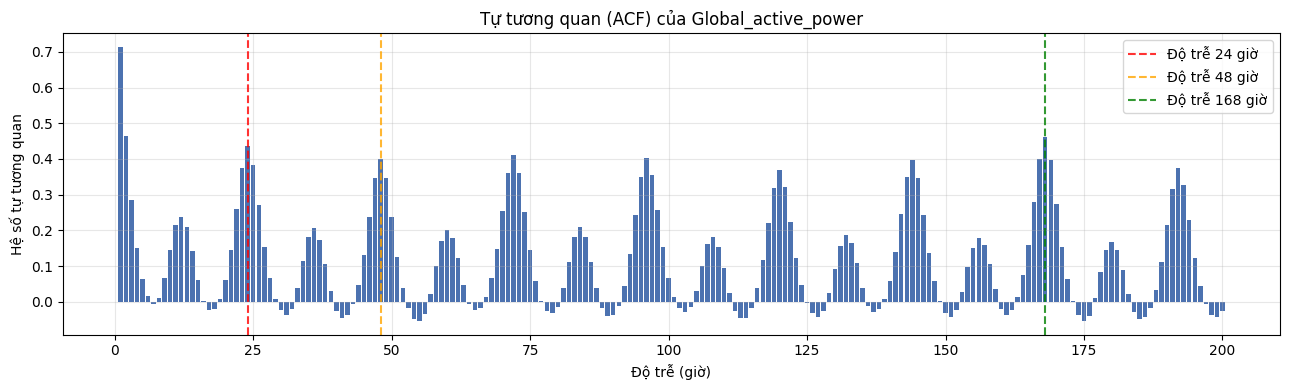

1      0.713
2      0.465
12     0.239
23     0.376
24     0.436
25     0.383
48     0.401
167    0.400
168    0.461
169    0.398
dtype: float64

In [34]:
lags = np.arange(1, 201)
acf = pd.Series([df[TARGET].autocorr(int(l)) for l in lags], index=lags)
a = acf.values
peaks = [(int(lags[i]), float(a[i])) for i in range(1, len(a) - 1) if a[i] > a[i - 1] and a[i] > a[i + 1]]
top_peaks = sorted(peaks, key=lambda t: -t[1])[:6]
print("Các đỉnh ACF cao nhất (độ trễ, hệ số):", [(l, round(v, 3)) for l, v in top_peaks])

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(acf.index, acf.values, width=0.8, color="#4C72B0")
for L, c in [(24, "red"), (48, "orange"), (168, "green")]:
    ax.axvline(L, color=c, linestyle="--", alpha=0.8, label=f"Độ trễ {L} giờ")
ax.set_title("Tự tương quan (ACF) của Global_active_power")
ax.set_xlabel("Độ trễ (giờ)"); ax.set_ylabel("Hệ số tự tương quan"); ax.legend()
plt.tight_layout()
save_fig("02_rq1_acf")
plt.show()
acf.loc[[1, 2, 12, 23, 24, 25, 48, 167, 168, 169]].round(3)

In [35]:
add_note("RQ1-chu kỳ", f"Hệ số tự tương quan tại độ trễ 1 giờ là {vn(acf.loc[1])}; tại 12 giờ là {vn(acf.loc[12])}; "
         f"tại 24 giờ là {vn(acf.loc[24])}; tại 48 giờ là {vn(acf.loc[48])}; tại 168 giờ là {vn(acf.loc[168])}.")
add_note("RQ1-chu kỳ", "Các đỉnh tự tương quan cao nhất (không kể độ trễ 1) xuất hiện tại độ trễ: " +
         ", ".join(f"{l} giờ ({vn(v)})" for l, v in top_peaks) + ".")

**Nhận xét:** Tự tương quan ở độ trễ 1 giờ là 0,713, độ trễ 24 giờ là 0,436 và độ trễ 168 giờ là 0,461 (cao nhất sau độ trễ 1); độ trễ 12 giờ chỉ 0,239. Chuỗi có chu kỳ ngày và tuần rõ. Đây là cơ sở để chọn đặc trưng trễ 1, 24 và 168 giờ.

## 8. RQ1 (f), bổ sung: Công tơ phụ theo giờ
Hình này giúp **giải thích** đỉnh công suất theo giờ: khu vực nào (bếp, phòng giặt, nước nóng và điều hòa) tăng vào thời điểm nào. Sub_metering là Wh tiêu thụ mỗi giờ (đã tổng hợp theo giờ ở bước làm sạch).

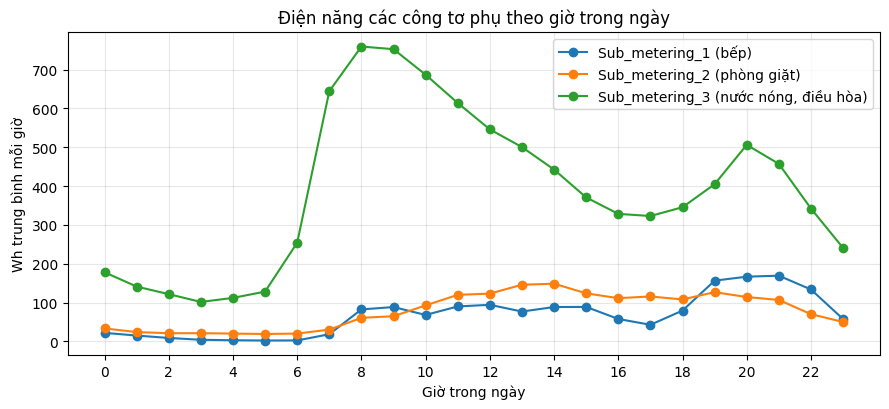

In [36]:
sub_prof = df.groupby("hour")[SUB_COLS].mean()
sub_prof.round(4).to_csv(DIR_DATA / "eda_rq1_submeter_theo_gio.csv", index_label="gio")
fig, ax = plt.subplots(figsize=(9, 4.2))
for c, lab in zip(SUB_COLS, ["Sub_metering_1 (bếp)", "Sub_metering_2 (phòng giặt)", "Sub_metering_3 (nước nóng, điều hòa)"]):
    ax.plot(sub_prof.index, sub_prof[c], marker="o", label=lab)
ax.set_title("Điện năng các công tơ phụ theo giờ trong ngày")
ax.set_xlabel("Giờ trong ngày"); ax.set_ylabel("Wh trung bình mỗi giờ"); ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout()
save_fig("02_rq1_submeter_theo_gio")
plt.show()

for c in SUB_COLS:
    h = int(sub_prof[c].idxmax())
    add_note("RQ1-công tơ phụ", f"{c} đạt trung bình cao nhất lúc {h}h ({vn(sub_prof.loc[h, c], 1)} Wh/giờ), thấp nhất lúc {int(sub_prof[c].idxmin())}h ({vn(sub_prof[c].min(), 1)} Wh/giờ).")

**Nhận xét:** Ba công tơ phụ có giờ cao điểm khác nhau: Sub_metering_3 (máy nước nóng, điều hòa) lúc 8h (759,5 Wh/giờ), Sub_metering_2 (phòng giặt) lúc 14h (148,5), Sub_metering_1 (bếp) lúc 21h (169,2). Cả ba cùng thấp nhất khoảng 3h đến 5h sáng. Mỗi nhóm thiết bị có giờ hoạt động riêng, góp phần giải thích hai đỉnh công suất trong ngày.

## Gợi ý nhận xét E0.7 (số tự điền)

In [37]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 01:41:19 | INFO | Gợi ý nhận xét E0.7 (số tự điền), lưu ở data/eda_E0.7_goi_y_nhan_xet.md:
- **[RQ1-chu kỳ]** Hệ số tự tương quan tại độ trễ 1 giờ là 0,713; tại 12 giờ là 0,239; tại 24 giờ là 0,436; tại 48 giờ là 0,401; tại 168 giờ là 0,461.
- **[RQ1-chu kỳ]** Các đỉnh tự tương quan cao nhất (không kể độ trễ 1) xuất hiện tại độ trễ: 168 giờ (0,461), 24 giờ (0,436), 72 giờ (0,412), 96 giờ (0,403), 48 giờ (0,401), 144 giờ (0,397).
- **[RQ1-công tơ phụ]** Sub_metering_1 đạt trung bình cao nhất lúc 21h (169,2 Wh/giờ), thấp nhất lúc 5h (2,1 Wh/giờ).
- **[RQ1-công tơ phụ]** Sub_metering_2 đạt trung bình cao nhất lúc 14h (148,5 Wh/giờ), thấp nhất lúc 5h (18,9 Wh/giờ).
- **[RQ1-công tơ phụ]** Sub_metering_3 đạt trung bình cao nhất lúc 8h (759,5 Wh/giờ), thấp nhất lúc 3h (101,5 Wh/giờ).


---
# Phần E0.8
> Nguồn: `notebooks/eda_notebooks/02_E0.8_rq2_tuong_quan_Han.ipynb`

In [38]:
MA_TN = "E0.8"
moc_note = len(notes)    # các câu gợi ý nhận xét từ đây trở đi thuộc E0.8

## 9. RQ2 (a): Biểu đồ phân tán
Mỗi chấm là một giờ. Có hơn 30 nghìn điểm nên dùng biểu đồ hexbin (màu càng đậm càng nhiều điểm, thang log) thay cho scatter thường để khỏi chồng lấn. Ô thứ sáu (Global_reactive_power) là biến bổ sung, không thuộc danh sách của RQ2.

Số giờ dùng cho tương quan (đủ 7 cột): 34.157


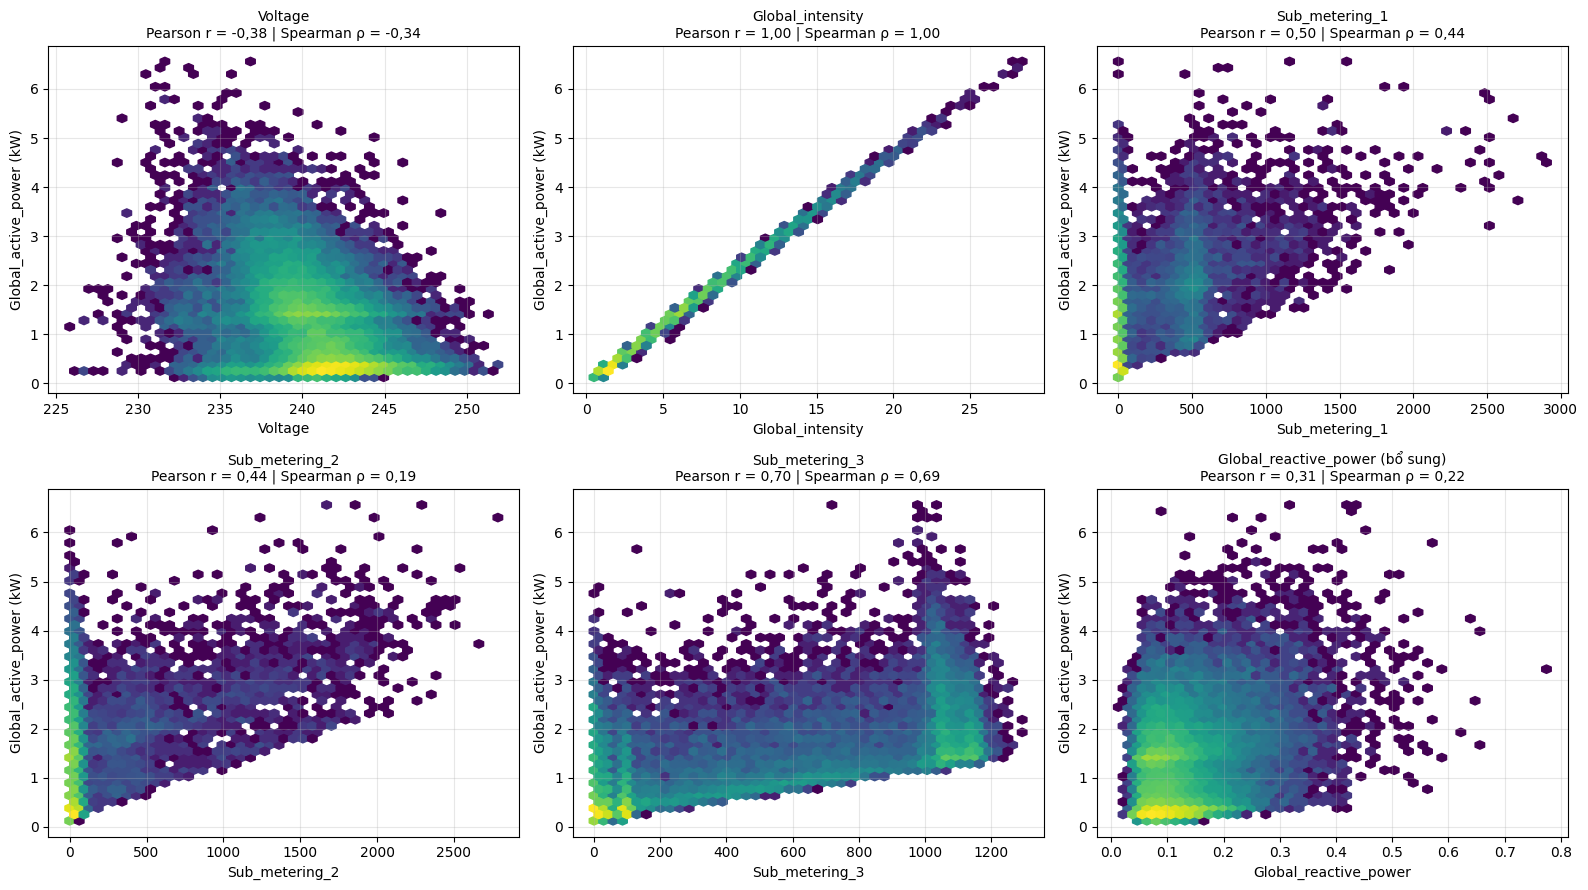

In [39]:
d2 = df[COLS].dropna()
print("Số giờ dùng cho tương quan (đủ 7 cột):", fmt(len(d2)))
pear = d2.corr(method="pearson")
spear = d2.corr(method="spearman")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), VAR_RQ2 + ["Global_reactive_power"]):
    hb = ax.hexbin(d2[c], d2[TARGET], gridsize=45, bins="log", mincnt=1, cmap="viridis")
    suffix = " (bổ sung)" if c == "Global_reactive_power" else ""
    ax.set_title(f"{c}{suffix}\nPearson r = {vn(pear.loc[c, TARGET], 2)} | Spearman ρ = {vn(spear.loc[c, TARGET], 2)}", fontsize=10)
    ax.set_xlabel(c); ax.set_ylabel("Global_active_power (kW)")
plt.tight_layout()
save_fig("02_rq2_scatter")
plt.show()

**Nhận xét:** Global_intensity nằm gần như trên một đường thẳng so với công suất (r = 0,999). Voltage có quan hệ nghịch yếu (r = −0,379). Sub_metering_3 có quan hệ dương trung bình (r = 0,696), còn Sub_metering_1 và 2 phân tán mạnh vì thiết bị chỉ bật trong thời gian ngắn.

## 10. RQ2 (b): Ma trận tương quan Pearson và Spearman
- **Pearson** đo quan hệ **tuyến tính**, nhạy với giá trị cực đoan.
- **Spearman** đo quan hệ **đơn điệu** (dựa trên thứ hạng), ít nhạy với ngoại lệ. Nếu hai hệ số chênh nhau nhiều thì quan hệ không tuyến tính hoặc chịu ảnh hưởng của giá trị cực đoan.
- Ngưỡng mô tả mức độ (quy ước chung): |r| ≥ 0,7 mạnh; 0,4 đến 0,7 trung bình; 0,2 đến 0,4 yếu; dưới 0,2 rất yếu.
- **Chỉ mô tả quan hệ, không suy diễn nhân quả.**

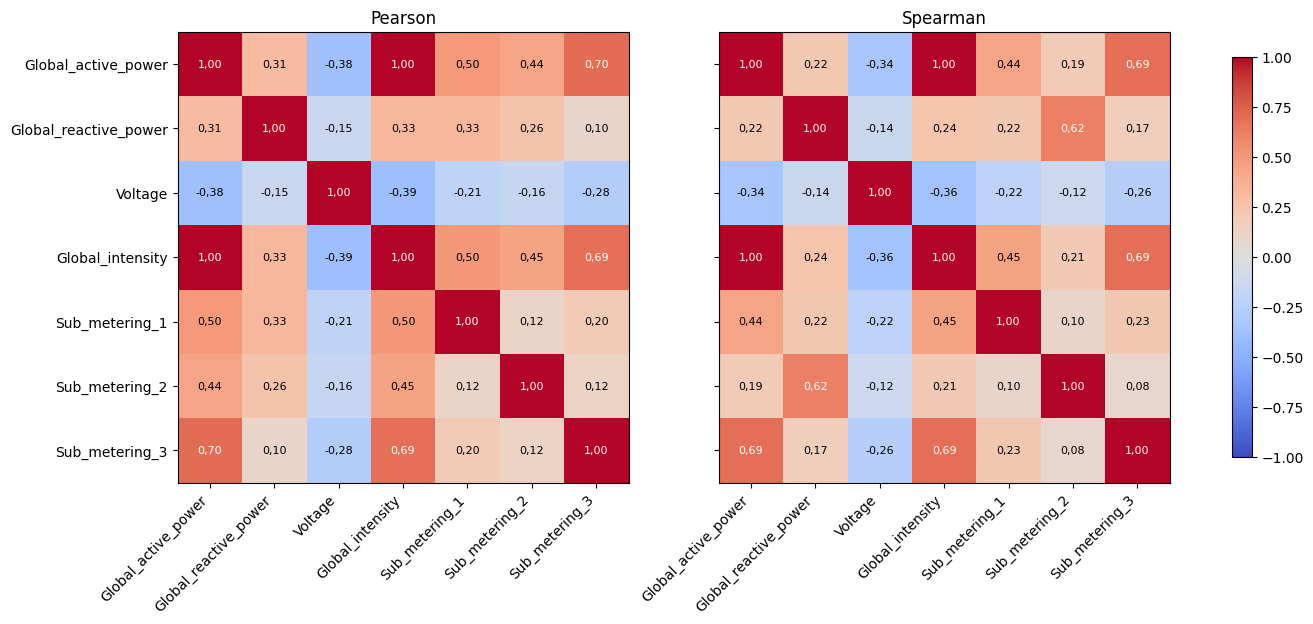

,Pearson,Spearman,Muc_do_Pearson,Muc_do_Spearman
Voltage,-0.379,-0.342,yếu,yếu
Global_intensity,0.999,0.998,mạnh,mạnh
Sub_metering_1,0.496,0.442,trung bình,trung bình
Sub_metering_2,0.440,0.188,trung bình,rất yếu
Sub_metering_3,0.696,0.694,trung bình,trung bình


In [40]:
def heat(ax, m, title, show_y=True):
    im = ax.imshow(m.values, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(m))); ax.set_yticks(range(len(m)))
    ax.set_xticklabels(m.columns, rotation=45, ha="right"); ax.set_yticklabels(m.index if show_y else [])
    for i in range(len(m)):
        for j in range(len(m)):
            ax.text(j, i, vn(m.values[i, j], 2), ha="center", va="center", fontsize=8,
                    color="white" if abs(m.values[i, j]) > 0.6 else "black")
    ax.set_title(title); ax.grid(False)
    return im

fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))
heat(ax[0], pear, "Pearson")
im = heat(ax[1], spear, "Spearman", show_y=False)
plt.colorbar(im, ax=list(ax), shrink=0.8)
save_fig("02_rq2_tuong_quan")
plt.show()

pear.round(4).to_csv(DIR_DATA / "eda_rq2_pearson.csv", index_label="bien")
spear.round(4).to_csv(DIR_DATA / "eda_rq2_spearman.csv", index_label="bien")

rq2 = pd.DataFrame({"Pearson": pear.loc[VAR_RQ2, TARGET], "Spearman": spear.loc[VAR_RQ2, TARGET]})
rq2["Muc_do_Pearson"] = rq2["Pearson"].map(strength)
rq2["Muc_do_Spearman"] = rq2["Spearman"].map(strength)
rq2.round(4).to_csv(DIR_DATA / "eda_rq2_voi_global_active_power.csv", index_label="bien")
rq2.round(3)

In [41]:
for c in VAR_RQ2:
    rp, rs = pear.loc[c, TARGET], spear.loc[c, TARGET]
    extra = " Hai hệ số chênh nhau trên 0,1: quan hệ có thể phi tuyến hoặc chịu ảnh hưởng của giá trị cực đoan." if abs(rp - rs) > 0.1 else ""
    add_note("RQ2", f"{c}: Pearson r = {vn(rp)} (mức {strength(rp)}); Spearman ρ = {vn(rs)} (mức {strength(rs)}).{extra}")

# Phần điện năng được ba công tơ phụ ghi nhận so với tổng điện năng cả hộ
e_total = (d2[TARGET] * 1000).sum()                  # kW trung bình mỗi giờ x 1000 = Wh mỗi giờ
share = {c: d2[c].sum() / e_total * 100 for c in SUB_COLS}
rest = 100 - sum(share.values())
add_note("RQ2-công tơ phụ", "Tỷ lệ điện năng ba công tơ phụ ghi nhận so với tổng điện năng cả hộ: " +
         "; ".join(f"{c} {vn(v, 1)}%" for c, v in share.items()) +
         f"; phần còn lại không qua công tơ phụ nào chiếm {vn(rest, 1)}%.")

**Nhận xét:** Global_intensity tương quan gần tuyệt đối với công suất (Pearson 0,999; Spearman 0,998) vì công suất bằng điện áp nhân cường độ, mà điện áp dao động rất ít; đây là quan hệ vật lý, không phải bằng chứng dự báo. Sub_metering_2 có Pearson 0,440 nhưng Spearman chỉ 0,188, chênh hơn 0,1, cho thấy quan hệ phi tuyến hoặc bị giá trị cực đoan chi phối. Voltage tương quan nghịch yếu (−0,379 và −0,342), phù hợp với việc lưới sụt áp khi nhiều thiết bị chạy cùng lúc. Tương quan không chứng minh quan hệ nhân quả.

## 11. RQ2 (c), bổ sung: Tương quan trễ (biến tại giờ t với công suất giờ t+1)
Đề tài **dự báo công suất của giờ t+1** và chỉ được dùng thông tin đến hết giờ t (Voltage, Global_intensity... của giờ t+1 là thông tin tương lai, không được đưa vào đầu vào). Vì vậy bảng này cho biết biến nào tại giờ t còn liên hệ với công suất giờ t+1. Đây là mô tả, không dùng để chọn mô hình.

In [42]:
tmp = df[COLS].copy()
tmp["GAP_t_cong_1"] = df[TARGET].shift(-1)      # công suất giờ t+1 (lưới giờ liên tục nên shift đúng nghĩa)
tmp = tmp.dropna()
lagged = pd.DataFrame({"Pearson": tmp.corr(method="pearson")["GAP_t_cong_1"].drop("GAP_t_cong_1"),
                       "Spearman": tmp.corr(method="spearman")["GAP_t_cong_1"].drop("GAP_t_cong_1")})
lagged.round(4).to_csv(DIR_DATA / "eda_rq2_tuong_quan_tre.csv", index_label="bien_tai_gio_t")
print("Số giờ dùng:", fmt(len(tmp)))
lagged.round(3)

Số giờ dùng: 34.144


,Pearson,Spearman
Global_active_power,0.713,0.756
Global_reactive_power,0.238,0.128
Voltage,-0.288,-0.272
Global_intensity,0.714,0.754
Sub_metering_1,0.297,0.319
Sub_metering_2,0.251,0.089
Sub_metering_3,0.455,0.474


In [43]:
order = lagged["Pearson"].abs().sort_values(ascending=False).index.tolist()
add_note("RQ2-tương quan trễ", "Tương quan Pearson giữa công suất giờ t+1 và biến tại giờ t, xếp từ cao xuống thấp: " +
         "; ".join(f"{c} {vn(lagged.loc[c, 'Pearson'])}" for c in order) + ".")
add_note("RQ2-so sánh", f"So sánh với tương quan cùng giờ: Global_intensity cùng giờ có r = {vn(pear.loc['Global_intensity', TARGET])}, "
         f"còn Global_intensity giờ t với công suất giờ t+1 có r = {vn(lagged.loc['Global_intensity', 'Pearson'])}.")

**Nhận xét:** Khi dự báo giờ t+1, tương quan với biến tại giờ t giảm rõ: Global_intensity chỉ còn 0,714 (so với 0,999 cùng giờ), ngang với chính công suất giờ t (0,713); tiếp theo là Sub_metering_3 (0,455), Sub_metering_1 (0,297), Voltage (−0,288), Sub_metering_2 (0,251), Global_reactive_power (0,238). Không biến nào còn trùng với nhãn, nên dùng các biến đo tại giờ t làm đặc trưng không gây rò rỉ dữ liệu.

## Gợi ý nhận xét E0.8 (số tự điền)

In [44]:
goi_y = "\n".join(notes[moc_note:])
(DIR_DATA / f"eda_{MA_TN}_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info(f"Gợi ý nhận xét {MA_TN} (số tự điền), lưu ở data/eda_data/eda_{MA_TN}_goi_y_nhan_xet.md:\n" + goi_y)

2026-11-14 01:41:20 | INFO | Gợi ý nhận xét E0.8 (số tự điền), lưu ở data/eda_E0.8_goi_y_nhan_xet.md:
- **[RQ2]** Voltage: Pearson r = -0,379 (mức yếu); Spearman ρ = -0,342 (mức yếu).
- **[RQ2]** Global_intensity: Pearson r = 0,999 (mức mạnh); Spearman ρ = 0,998 (mức mạnh).
- **[RQ2]** Sub_metering_1: Pearson r = 0,496 (mức trung bình); Spearman ρ = 0,442 (mức trung bình).
- **[RQ2]** Sub_metering_2: Pearson r = 0,440 (mức trung bình); Spearman ρ = 0,188 (mức rất yếu). Hai hệ số chênh nhau trên 0,1: quan hệ có thể phi tuyến hoặc chịu ảnh hưởng của giá trị cực đoan.
- **[RQ2]** Sub_metering_3: Pearson r = 0,696 (mức trung bình); Spearman ρ = 0,694 (mức trung bình).
- **[RQ2-công tơ phụ]** Tỷ lệ điện năng ba công tơ phụ ghi nhận so với tổng điện năng cả hộ: Sub_metering_1 6,2%; Sub_metering_2 7,1%; Sub_metering_3 35,5%; phần còn lại không qua công tơ phụ nào chiếm 51,2%.
- **[RQ2-tương quan trễ]** Tương quan Pearson giữa công suất giờ t+1 và biến tại giờ t, xếp từ cao xuống thấp: Global_

---
# Tổng hợp toàn bộ EDA
Bảng khó khăn dữ liệu (E0.1 → E0.3) và các câu gợi ý nhận xét có số tự điền (E0.4 → E0.8).

In [45]:
bang_kk = pd.DataFrame(kho_khan)
bang_kk.index = range(1, len(bang_kk) + 1)
bang_kk.to_csv(DIR_DATA / "eda_00_kho_khan_xu_ly.csv", encoding="utf-8-sig", index_label="STT")
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)

tom_tat = (f"EDA dữ liệu thô: {fmt(n_dong)} dòng × {n_cot} cột, mỗi phút 1 dòng, "
           f"từ {ts.iloc[0]:%d/%m/%Y %H:%M} đến {ts.iloc[-1]:%d/%m/%Y %H:%M}.\n"
           + "\n".join(f"  {i}. {r['Khó khăn']}: {r['Bằng chứng (số thật)']} → {r['Cách xử lý']} ({r['Xử lý ở đâu']})."
                       for i, r in bang_kk.iterrows()))
(DIR_DATA / "eda_00_tom_tat.txt").write_text(tom_tat, encoding="utf-8")

goi_y = "# Câu gợi ý nhận xét EDA (số liệu tự điền từ các notebook E0.4 → E0.8)\n\n" + "\n".join(notes)
(DIR_DATA / "eda_goi_y_nhan_xet.md").write_text(goi_y, encoding="utf-8")
log.info("Tóm tắt khó khăn dữ liệu:\n" + tom_tat)
log.info(goi_y)

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
1,Giá trị thiếu ghi theo 2 kiểu khác nhau,6 cột ghi thiếu bằng '?' (25.979 dòng mỗi cột); Sub_metering_3 để trống (25.979 dòng). Đọc mặc định thì 6/7 cột đo thành chuỗi,"Khai báo na_values='?' khi đọc để mọi cột đo thành số, ô trống tự thành NaN","01_cleaning, mục 1"
2,"Thời gian lưu ở 2 cột chuỗi, định dạng ngày kiểu Pháp","Date dạng dd/mm/yyyy, Time dạng hh:mm:ss; 2.075.259 dòng, bước 1 phút, 0 mốc trùng","Gộp Date và Time thành datetime với format '%d/%m/%Y %H:%M:%S' (không để pandas tự đoán, tránh lẫn ngày/tháng)","01_cleaning, mục 1"
3,Tháng đầu và tháng cuối không đủ,"2006-12 chỉ có 49% số phút, 2010-11 có 86%",Không so sánh trực tiếp 2 tháng này với tháng khác; khi tính trung bình theo năm dùng năm vận hành tháng 12 đến tháng 11,02_E0.6 (xu hướng dài hạn)
4,"Thiếu thành từng khoảng liền nhau, có khoảng kéo dài nhiều ngày","25.979 phút thiếu (1.25%) chia thành 71 khoảng; 7 khoảng dài hơn 2 giờ, dài nhất 120.4 giờ; thiếu dồn vào vài tháng (cao nhất 08/2010: 16.2%)",Không điền nhãn mục tiêu; đầu vào chỉ điền tiến tối đa 2 giờ và có cờ báo thiếu; khoảng dài để NaN,"01_cleaning, mục 4 và 8"
5,"Phân bố lệch phải, công tơ phụ phần lớn bằng 0","Global_active_power skew = 1.79; Sub_metering_1 bằng 0 ở 91.7% số phút, Sub_metering_2 70.1%","Ngoại lệ theo IQR chỉ đánh dấu, không xoá (đỉnh tiêu thụ là hành vi thật); với công tơ phụ IQR không dùng được vì đa số bằng 0","01_cleaning, mục 6"
6,Các cột khác đơn vị và khác thang đo,"kW, kVAR, V, A, Wh/phút; Voltage quanh 241 V trong khi công suất quanh 1.09 kW","Khi gộp theo giờ: lấy trung bình cho 4 biến điện, lấy tổng cho 3 công tơ phụ (Wh); Linear Regression dùng StandardScaler","01_cleaning, mục 7; pipeline mô hình"
7,Global_intensity gần như trùng với biến mục tiêu,"r = 0.999 ở mức phút, vì công suất ≈ điện áp × dòng điện",Không dùng Global_intensity của cùng giờ cần dự báo; chỉ dùng giá trị của các giờ trước (trễ) làm đặc trưng,03_features
8,Tổng công tơ phụ đôi khi lớn hơn điện năng cả hộ,"1.050 phút (0.051%), lệch nhiều nhất 2.4 Wh","Chỉ ghi nhận, không sửa (sai số làm tròn và sai số đo của công tơ)","01_cleaning, mục 5"
9,Dữ liệu mức phút rất nhiễu,Trung bình mỗi phút công suất đổi 0.084 kW; 1.93% số lần đổi hơn 1 kW trong 1 phút,Gộp thành trung bình theo giờ và dự báo giờ kế tiếp (giờ hợp lệ khi có ít nhất 30 phút đo được),"01_cleaning, mục 7"


2026-11-14 01:41:20 | INFO | Tóm tắt khó khăn dữ liệu:
EDA dữ liệu thô: 2.075.259 dòng × 9 cột, mỗi phút 1 dòng, từ 16/12/2006 17:24 đến 26/11/2010 21:02.
  1. Giá trị thiếu ghi theo 2 kiểu khác nhau: 6 cột ghi thiếu bằng '?' (25.979 dòng mỗi cột); Sub_metering_3 để trống (25.979 dòng). Đọc mặc định thì 6/7 cột đo thành chuỗi → Khai báo na_values='?' khi đọc để mọi cột đo thành số, ô trống tự thành NaN (01_cleaning, mục 1).
  2. Thời gian lưu ở 2 cột chuỗi, định dạng ngày kiểu Pháp: Date dạng dd/mm/yyyy, Time dạng hh:mm:ss; 2.075.259 dòng, bước 1 phút, 0 mốc trùng → Gộp Date và Time thành datetime với format '%d/%m/%Y %H:%M:%S' (không để pandas tự đoán, tránh lẫn ngày/tháng) (01_cleaning, mục 1).
  3. Tháng đầu và tháng cuối không đủ: 2006-12 chỉ có 49% số phút, 2010-11 có 86% → Không so sánh trực tiếp 2 tháng này với tháng khác; khi tính trung bình theo năm dùng năm vận hành tháng 12 đến tháng 11 (02_E0.6 (xu hướng dài hạn)).
  4. Thiếu thành từng khoảng liền nhau, có khoảng kéo dài n

2026-11-14 01:41:20 | INFO | # Câu gợi ý nhận xét EDA (số liệu tự điền từ các notebook E0.4 → E0.8)

- **[Phân bố]** Công suất trung bình theo giờ có trung bình 1,092 kW, trung vị 0,803 kW, độ lệch chuẩn 0,898 kW; giá trị nhỏ nhất 0,124 kW và lớn nhất 6,561 kW. Độ lệch (skewness) bằng 1,30, phân bố lệch phải: phần lớn các giờ tiêu thụ thấp, thỉnh thoảng có giờ tiêu thụ cao.
- **[RQ1-giờ]** Công suất trung bình cao nhất lúc 20h (1,899 kW) và thấp nhất lúc 4h (0,444 kW), gấp 4,3 lần. Đỉnh trong khung 5h–12h là lúc 7h (1,502 kW); đỉnh trong khung 17h–23h là lúc 20h (1,899 kW).
- **[RQ1-cuối tuần]** Trung bình cả ngày: ngày thường 1,035 kW, cuối tuần 1,234 kW; cuối tuần cao hơn ngày thường 19,2%.
- **[RQ1-cuối tuần]** Chênh lệch giữa cuối tuần và ngày thường lớn nhất lúc 7h: cuối tuần thấp hơn 0,754 kW (0,961 so với 1,715 kW).
- **[RQ1-thứ]** Thứ có công suất trung bình cao nhất là T7 (1,248 kW), thấp nhất là T5 (0,982 kW); chênh nhau 27,2%.
- **[RQ1-mùa]** Tháng có công suất trung bình ca

## Nhật ký

- 13/11/2026 – Gộp 8 notebook EDA con (E0.1 → E0.8) thành bản hoàn chỉnh `00_EDA_tong_hop_Han.ipynb` bằng script `gop_eda.py`. Commit `...`.